# Global Development Measurement — Week 2 Clustering

## Objective
Create one average development profile per country, compare multiple clustering algorithms, interpret the resulting groups, and select a defensible model using quantitative metrics.

**Important modelling choice:** the source has 2,704 rows for 208 countries (13 rows per country) and no explicit year column. This notebook averages numeric indicators by country, so the clustering unit is a country-level average profile—not an individual source row.

**Reproducibility:** run the notebook from top to bottom. The saved outputs have been cleared so old results cannot be mistaken for results from the revised code. Keep `World_development_mesurement.xlsx` in the same folder as this notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df = pd.read_excel("World_development_mesurement.xlsx")
df.head()

,Birth Rate,Business Tax Rate,CO2 Emissions,Country,Days to Start Business,Ease of Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,...,Life Expectancy Male,Mobile Phone Usage,Number of Records,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
0,0.020,NaN,87931.0,Algeria,NaN,NaN,26998.0,"$54,790,058,957",0.035,$60,...,67.0,0.0,1,0.342,0.619,0.039,31719449,0.599,"$102,000,000","$193,000,000"
1,0.050,NaN,9542.0,Angola,NaN,NaN,7499.0,"$9,129,594,819",0.034,$22,...,44.0,0.0,1,0.476,0.499,0.025,13924930,0.324,"$34,000,000","$146,000,000"
2,0.043,NaN,1617.0,Benin,NaN,NaN,1983.0,"$2,359,122,303",0.043,$15,...,53.0,0.0,1,0.454,0.517,0.029,6949366,0.383,"$77,000,000","$50,000,000"
3,0.027,NaN,4276.0,Botswana,NaN,NaN,1836.0,"$5,788,311,645",0.047,$152,...,49.0,0.1,1,0.383,0.587,0.029,1755375,0.532,"$227,000,000","$209,000,000"
4,0.046,NaN,1041.0,Burkina Faso,NaN,NaN,NaN,"$2,610,959,139",0.051,$12,...,49.0,0.0,1,0.468,0.505,0.028,11607944,0.178,"$23,000,000","$30,000,000"


In [3]:
df.shape

(2704, 25)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2704 entries, 0 to 2703
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Birth Rate              2585 non-null   float64
 1   Business Tax Rate       1423 non-null   object 
 2   CO2 Emissions           2125 non-null   float64
 3   Country                 2704 non-null   object 
 4   Days to Start Business  1718 non-null   float64
 5   Ease of Business        185 non-null    float64
 6   Energy Usage            1785 non-null   float64
 7   GDP                     2494 non-null   object 
 8   Health Exp % GDP        2395 non-null   float64
 9   Health Exp/Capita       2395 non-null   object 
 10  Hours to do Tax         1416 non-null   float64
 11  Infant Mortality Rate   2444 non-null   float64
 12  Internet Usage          2531 non-null   float64
 13  Lending Interest        1880 non-null   float64
 14  Life Expectancy Female  2568 non-null   

In [5]:
df.columns

Index(['Birth Rate', 'Business Tax Rate', 'CO2 Emissions', 'Country',
       'Days to Start Business', 'Ease of Business', 'Energy Usage', 'GDP',
       'Health Exp % GDP', 'Health Exp/Capita', 'Hours to do Tax',
       'Infant Mortality Rate', 'Internet Usage', 'Lending Interest',
       'Life Expectancy Female', 'Life Expectancy Male', 'Mobile Phone Usage',
       'Number of Records', 'Population 0-14', 'Population 15-64',
       'Population 65+', 'Population Total', 'Population Urban',
       'Tourism Inbound', 'Tourism Outbound'],
      dtype='object')

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Birth Rate,2585.0,NaN,NaN,NaN,0.022715,0.011338,0.007,0.013,0.02,0.031,0.053
Business Tax Rate,1423,447,44.1%,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CO2 Emissions,2125.0,NaN,NaN,NaN,142307.107765,615928.805709,7.0,1360.0,8529.0,59108.0,8286892.0
Country,2704,208,Algeria,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Days to Start Business,1718.0,NaN,NaN,NaN,39.999418,57.318588,1.0,13.0,26.0,45.0,694.0
Ease of Business,185.0,NaN,NaN,NaN,94.875676,54.791906,1.0,48.0,94.0,142.0,189.0
Energy Usage,1785.0,NaN,NaN,NaN,77236.840896,259923.855845,8.0,3737.0,14338.0,41852.0,2727728.0
GDP,2494,2494,"$54,790,058,957",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Health Exp % GDP,2395.0,NaN,NaN,NaN,0.06417,0.026325,0.008,0.046,0.061,0.079,0.225
Health Exp/Capita,2395,1069,$15,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df["Country"].nunique()

208

In [8]:
df["Country"].value_counts().head(20)

Country
Algeria                 13
Angola                  13
Turkey                  13
Ukraine                 13
United Kingdom          13
Bahrain                 13
Iran, Islamic Rep.      13
Iraq                    13
Israel                  13
Jordan                  13
Kuwait                  13
Lebanon                 13
Oman                    13
Qatar                   13
Saudi Arabia            13
Syrian Arab Republic    13
United Arab Emirates    13
Yemen, Rep.             13
American Samoa          13
Australia               13
Name: count, dtype: int64

In [9]:
df["Country"].value_counts().value_counts()

count
13    208
Name: count, dtype: int64

In [10]:
''' Missing or NULL Values'''

missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100})

missing.sort_values("Missing_Percentage", ascending=False)

,Missing_Count,Missing_Percentage
Ease of Business,2519,93.158284
Hours to do Tax,1288,47.633136
Business Tax Rate,1281,47.374260
Days to Start Business,986,36.464497
Energy Usage,919,33.986686
Lending Interest,824,30.473373
CO2 Emissions,579,21.412722
Tourism Outbound,471,17.418639
Tourism Inbound,368,13.609467
Health Exp % GDP,309,11.427515


In [11]:
''' Duplicate's '''

df.duplicated().sum()

np.int64(0)

In [12]:
df[df.duplicated()]

,Birth Rate,Business Tax Rate,CO2 Emissions,Country,Days to Start Business,Ease of Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,...,Life Expectancy Male,Mobile Phone Usage,Number of Records,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound


In [13]:
df[df['Country']=='India'].T

,63,271,479,687,895,1103,1311,1519,1727,1935,2143,2351,2559
Birth Rate,0.026,0.025,0.025,0.024,0.024,0.023,0.023,0.022,0.022,0.022,0.021,0.021,0.021
Business Tax Rate,NaN,NaN,NaN,NaN,NaN,66.6%,74.0%,72.7%,70.3%,66.0%,64.9%,62.9%,62.8%
CO2 Emissions,1186663.0,1203843.0,1226791.0,1281914.0,1348525.0,1411128.0,1504365.0,1611404.0,1811289.0,1982263.0,2008823.0,NaN,NaN
Country,India,India,India,India,India,India,India,India,India,India,India,India,India
Days to Start Business,NaN,NaN,NaN,89.0,89.0,71.0,35.0,33.0,30.0,30.0,29.0,29.0,27.0
Ease of Business,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,131.0
Energy Usage,457198.0,464501.0,477540.0,489507.0,519165.0,539388.0,567182.0,604659.0,632956.0,698360.0,723743.0,749447.0,NaN
GDP,"$476,609,148,166","$493,954,333,981","$523,968,561,884","$618,356,467,438","$721,585,608,184","$834,215,013,605","$949,116,769,619","$1,238,700,195,644","$1,224,097,069,460","$1,365,372,433,342","$1,708,458,876,830","$1,880,100,141,185","$1,858,744,737,180"
Health Exp % GDP,0.043,0.045,0.044,0.043,0.045,0.042,0.04,0.039,0.039,0.039,0.037,0.039,0.04
Health Exp/Capita,$20,$21,$21,$24,$29,$32,$33,$40,$43,$44,$52,$62,$61


In [14]:
numeric_cols = df.select_dtypes(include=np.number).columns
numeric_cols

Index(['Birth Rate', 'CO2 Emissions', 'Days to Start Business',
       'Ease of Business', 'Energy Usage', 'Health Exp % GDP',
       'Hours to do Tax', 'Infant Mortality Rate', 'Internet Usage',
       'Lending Interest', 'Life Expectancy Female', 'Life Expectancy Male',
       'Mobile Phone Usage', 'Number of Records', 'Population 0-14',
       'Population 15-64', 'Population 65+', 'Population Total',
       'Population Urban'],
      dtype='object')

In [15]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Birth Rate,2585.0,2.271489e-02,1.133843e-02,0.007,0.01300,2.000000e-02,3.100000e-02,5.300000e-02
CO2 Emissions,2125.0,1.423071e+05,6.159288e+05,7.000,1360.00000,8.529000e+03,5.910800e+04,8.286892e+06
Days to Start Business,1718.0,3.999942e+01,5.731859e+01,1.000,13.00000,2.600000e+01,4.500000e+01,6.940000e+02
Ease of Business,185.0,9.487568e+01,5.479191e+01,1.000,48.00000,9.400000e+01,1.420000e+02,1.890000e+02
Energy Usage,1785.0,7.723684e+04,2.599239e+05,8.000,3737.00000,1.433800e+04,4.185200e+04,2.727728e+06
Health Exp % GDP,2395.0,6.416952e-02,2.632460e-02,0.008,0.04600,6.100000e-02,7.900000e-02,2.250000e-01
Hours to do Tax,1416.0,3.020685e+02,2.732997e+02,12.000,156.00000,2.390000e+02,3.447500e+02,2.600000e+03
Infant Mortality Rate,2444.0,3.281301e-02,2.996760e-02,0.002,0.00900,2.000000e-02,5.300000e-02,1.410000e-01
Internet Usage,2531.0,2.397471e-01,2.601318e-01,0.000,0.00000,1.000000e-01,4.000000e-01,1.000000e+00
Lending Interest,1880.0,1.481027e-01,1.718291e-01,0.005,0.08000,1.200000e-01,1.730000e-01,4.965000e+00


In [16]:
df_clean = df.copy()

In [17]:
money_cols = ["GDP","Health Exp/Capita","Tourism Inbound","Tourism Outbound"]

for col in money_cols:
    df_clean[col] = (
        df_clean[col]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .replace("nan", np.nan)
        .astype(float)
    )

In [18]:
df_clean["Business Tax Rate"] = (
    df_clean["Business Tax Rate"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .replace("nan", np.nan)
    .astype(float))

In [19]:
df_clean[money_cols + ["Business Tax Rate"]].dtypes

GDP                  float64
Health Exp/Capita    float64
Tourism Inbound      float64
Tourism Outbound     float64
Business Tax Rate    float64
dtype: object

In [20]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2704 entries, 0 to 2703
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Birth Rate              2585 non-null   float64
 1   Business Tax Rate       1423 non-null   float64
 2   CO2 Emissions           2125 non-null   float64
 3   Country                 2704 non-null   object 
 4   Days to Start Business  1718 non-null   float64
 5   Ease of Business        185 non-null    float64
 6   Energy Usage            1785 non-null   float64
 7   GDP                     2494 non-null   float64
 8   Health Exp % GDP        2395 non-null   float64
 9   Health Exp/Capita       2395 non-null   float64
 10  Hours to do Tax         1416 non-null   float64
 11  Infant Mortality Rate   2444 non-null   float64
 12  Internet Usage          2531 non-null   float64
 13  Lending Interest        1880 non-null   float64
 14  Life Expectancy Female  2568 non-null   

In [21]:
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()

numeric_cols

['Birth Rate',
 'Business Tax Rate',
 'CO2 Emissions',
 'Days to Start Business',
 'Ease of Business',
 'Energy Usage',
 'GDP',
 'Health Exp % GDP',
 'Health Exp/Capita',
 'Hours to do Tax',
 'Infant Mortality Rate',
 'Internet Usage',
 'Lending Interest',
 'Life Expectancy Female',
 'Life Expectancy Male',
 'Mobile Phone Usage',
 'Number of Records',
 'Population 0-14',
 'Population 15-64',
 'Population 65+',
 'Population Total',
 'Population Urban',
 'Tourism Inbound',
 'Tourism Outbound']

In [22]:
df_clean[numeric_cols].nunique().sort_values()

Number of Records            1
Internet Usage              11
Mobile Phone Usage          26
Life Expectancy Male        47
Birth Rate                  47
Life Expectancy Female      49
Days to Start Business     126
Infant Mortality Rate      129
Health Exp % GDP           145
Ease of Business           185
Population 65+             208
Hours to do Tax            280
Population 15-64           298
Lending Interest           351
Population 0-14            376
Business Tax Rate          447
Population Urban           822
Health Exp/Capita         1069
Tourism Outbound          1457
Tourism Inbound           1650
Energy Usage              1721
CO2 Emissions             1743
GDP                       2494
Population Total          2699
dtype: int64

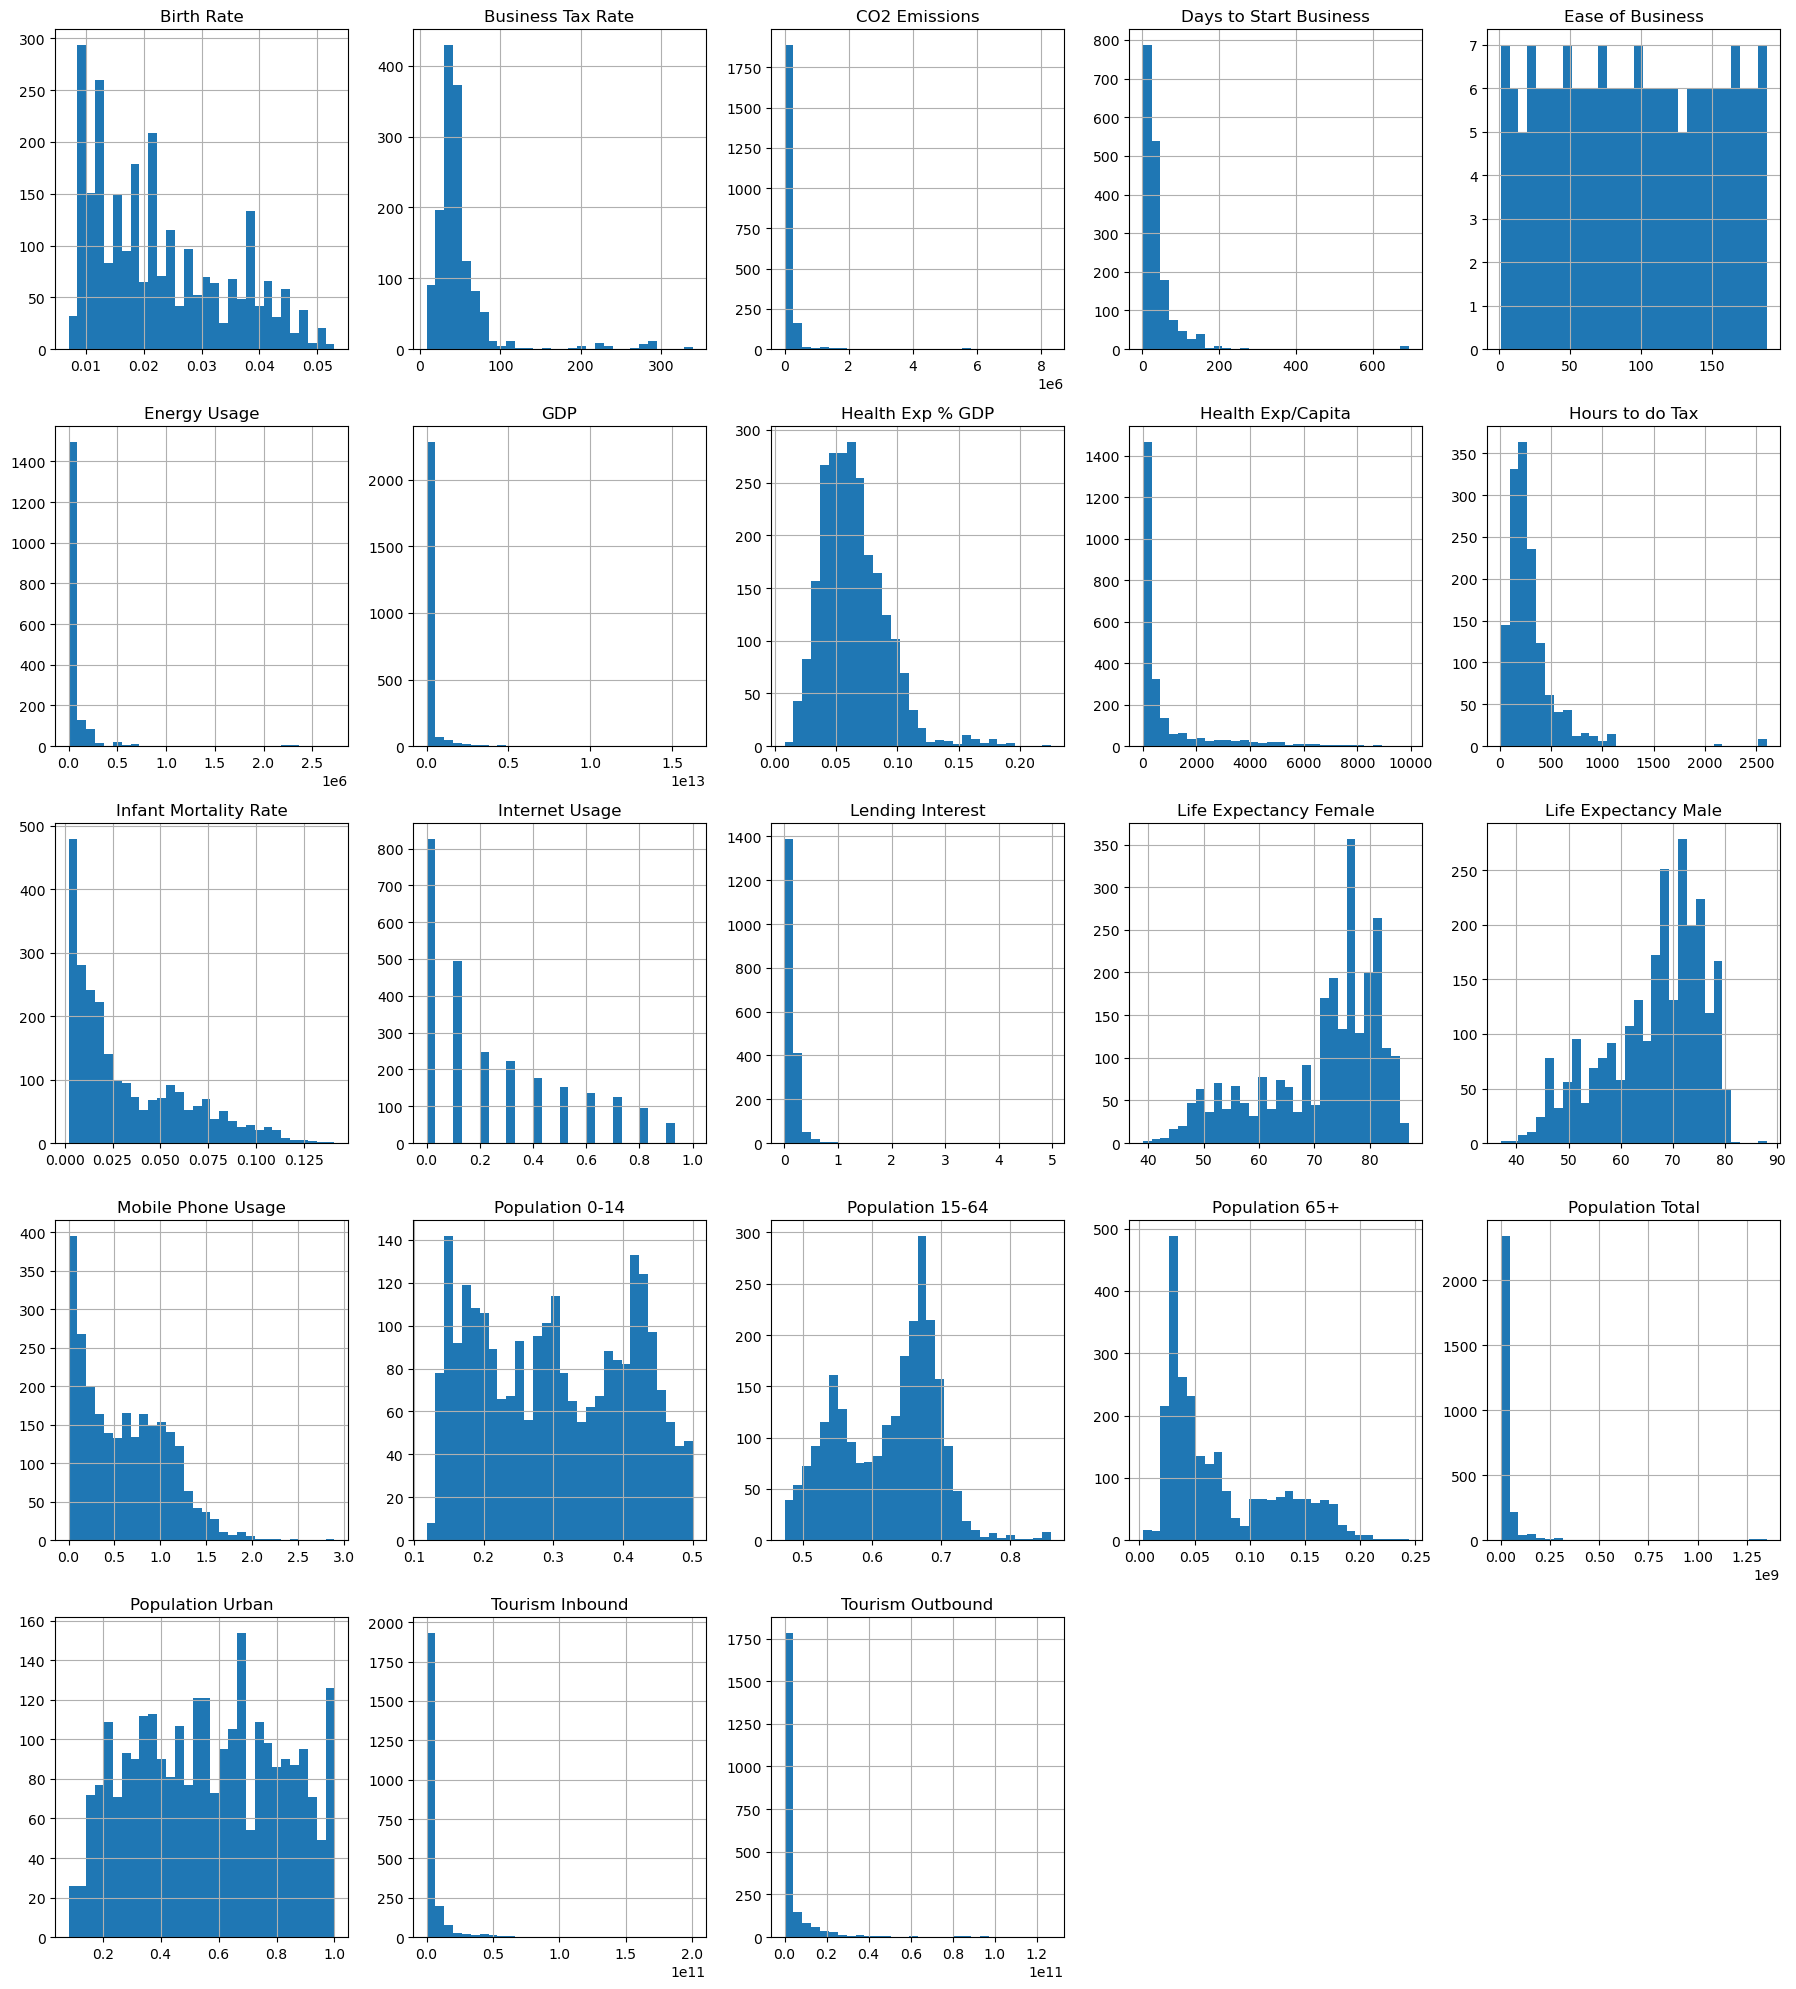

In [23]:
numeric_features = [col for col in numeric_cols if df_clean[col].nunique(dropna=True) > 1]

df_clean[numeric_features].hist(figsize=(18, 20),bins=30)

plt.tight_layout()
plt.show()

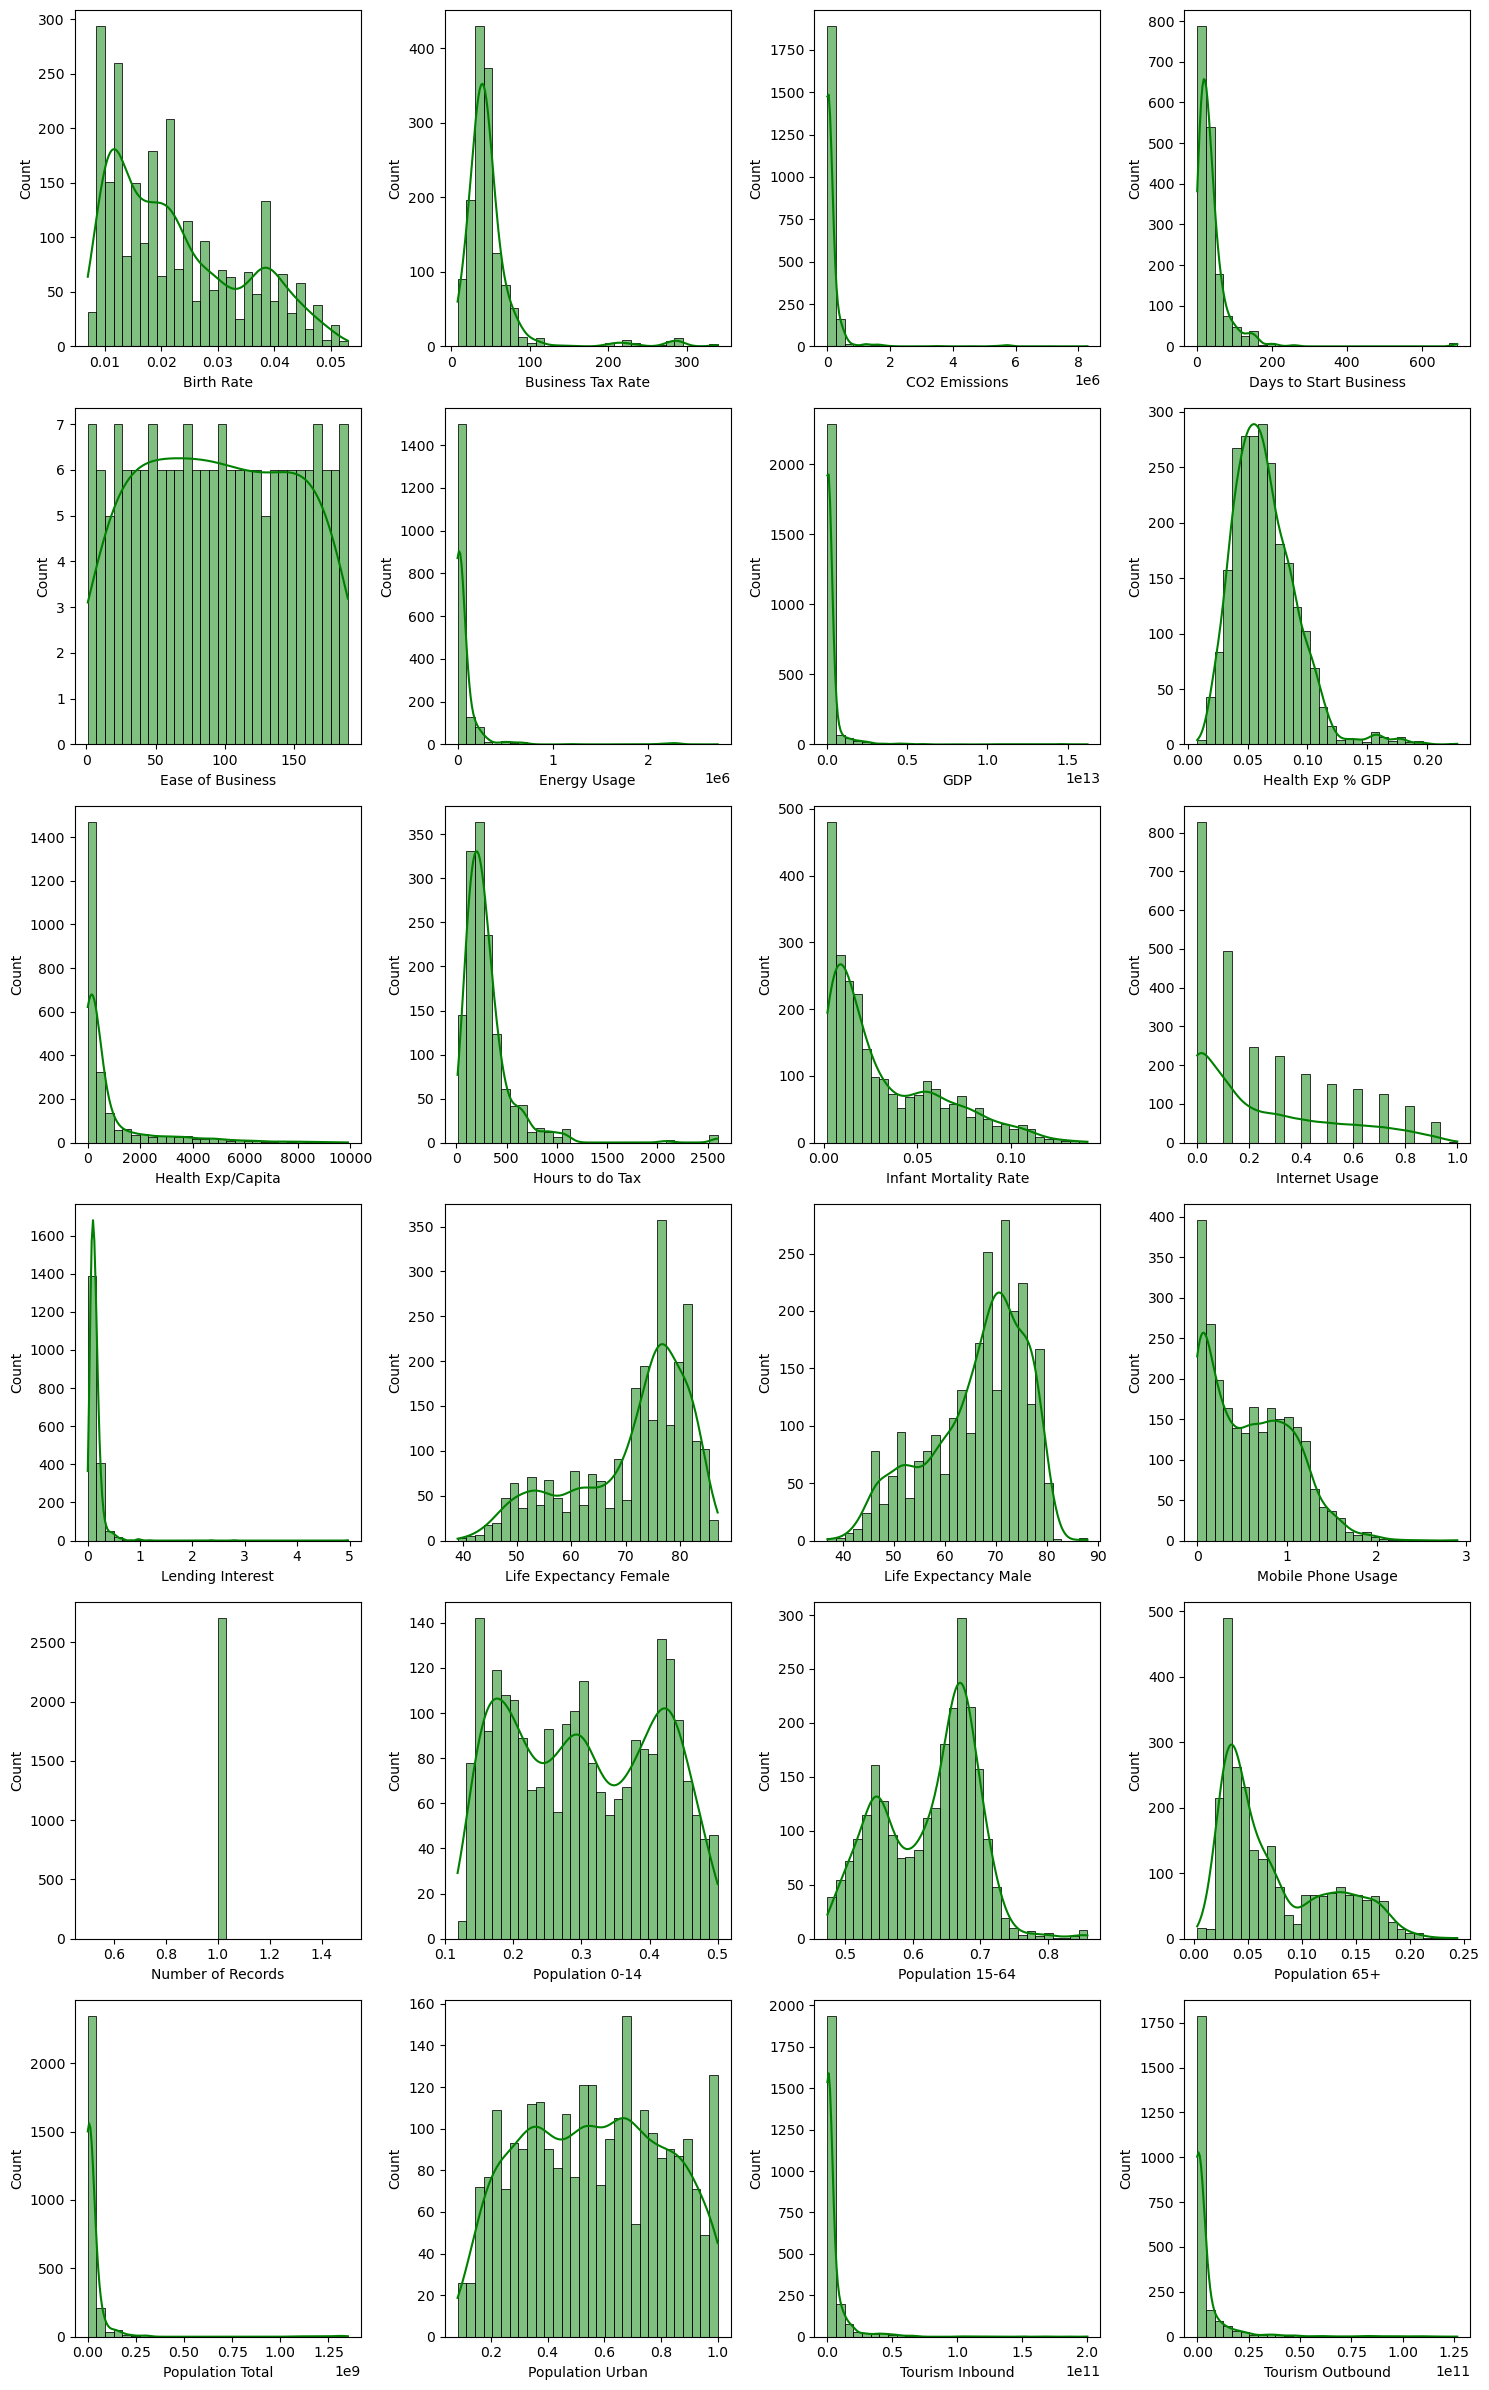

In [24]:
import math

n_cols = 4
n_rows = math.ceil(len(numeric_cols)/n_cols)

fig, axis = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axis = axis.flatten()


for i,col in enumerate(df_clean[numeric_cols]):
    sns.histplot(data = df_clean[col],ax = axis[i],kde = True,bins = 30, color = "green")

plt.tight_layout()
plt.show()

In [25]:
skewness = (df_clean[numeric_features].skew().sort_values(ascending=False))
skewness

Lending Interest          15.536119
GDP                        9.424247
Population Total           8.788164
CO2 Emissions              8.654039
Days to Start Business     7.437592
Tourism Inbound            7.114871
Energy Usage               7.062230
Tourism Outbound           5.210304
Hours to do Tax            4.491308
Business Tax Rate          4.342568
Health Exp/Capita          2.817482
Health Exp % GDP           1.179757
Infant Mortality Rate      1.049118
Internet Usage             0.940966
Population 65+             0.919841
Birth Rate                 0.662151
Mobile Phone Usage         0.569605
Population 0-14            0.059660
Ease of Business           0.017745
Population Urban           0.012519
Population 15-64          -0.186881
Life Expectancy Male      -0.705485
Life Expectancy Female    -0.891556
dtype: float64

In [26]:
eda_summary = pd.DataFrame({
    "Missing_%": df_clean[numeric_features].isna().mean() * 100,
    "Mean": df_clean[numeric_features].mean(),
    "Median": df_clean[numeric_features].median(),
    "Std": df_clean[numeric_features].std(),
    "Skewness": df_clean[numeric_features].skew(),
    "Unique_Values": df_clean[numeric_features].nunique()
})

eda_summary.sort_values("Skewness", ascending=False)

,Missing_%,Mean,Median,Std,Skewness,Unique_Values
Lending Interest,30.473373,1.481027e-01,1.200000e-01,1.718291e-01,15.536119,351
GDP,7.766272,2.638540e+11,1.507975e+10,1.129910e+12,9.424247,2494
Population Total,0.000000,3.145729e+07,5.800324e+06,1.242894e+08,8.788164,2699
CO2 Emissions,21.412722,1.423071e+05,8.529000e+03,6.159288e+05,8.654039,1743
Days to Start Business,36.464497,3.999942e+01,2.600000e+01,5.731859e+01,7.437592,126
Tourism Inbound,13.609467,4.939320e+09,6.885000e+08,1.385098e+10,7.114871,1650
Energy Usage,33.986686,7.723684e+04,1.433800e+04,2.599239e+05,7.062230,1721
Tourism Outbound,17.418639,4.729435e+09,4.560000e+08,1.326774e+10,5.210304,1457
Hours to do Tax,47.633136,3.020685e+02,2.390000e+02,2.732997e+02,4.491308,280
Business Tax Rate,47.374260,4.896690e+01,4.100000e+01,4.095412e+01,4.342568,447


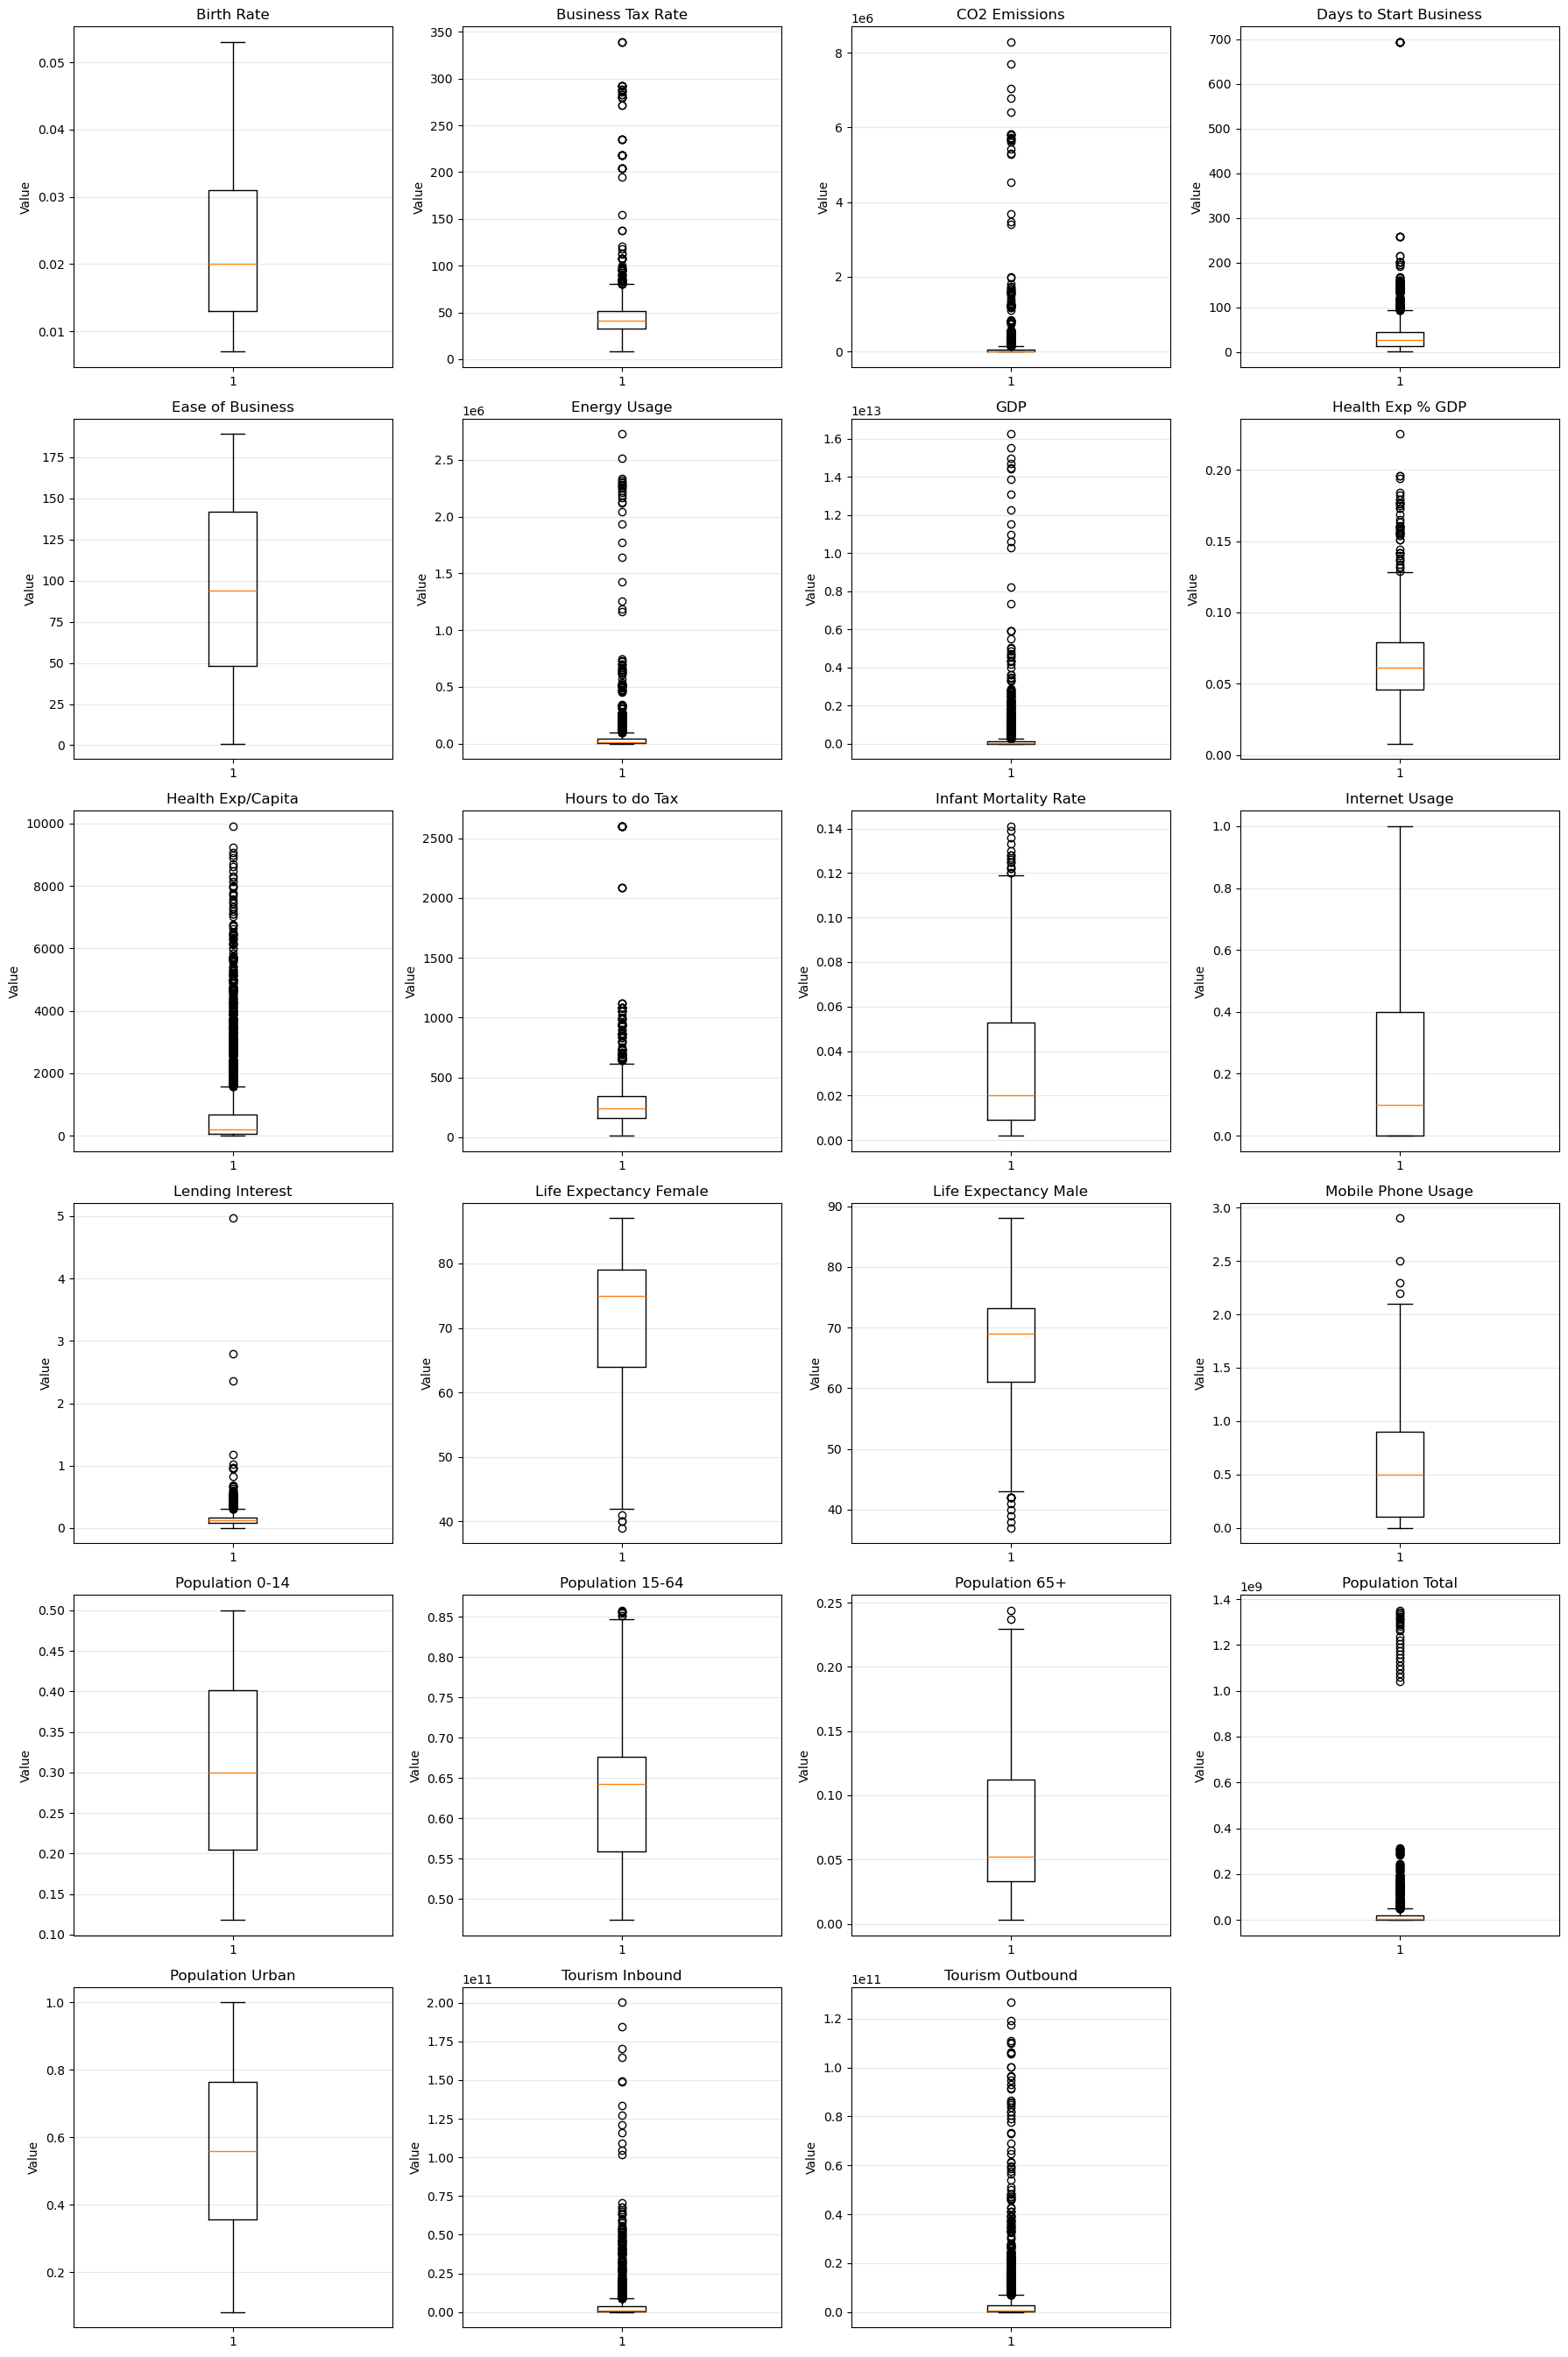

In [27]:
import math
import numpy as np
import matplotlib.pyplot as plt

numeric_features = [col for col in df_clean.select_dtypes(include=np.number).columns if df_clean[col].nunique(dropna=True) > 1]

n_features = len(numeric_features)
ncols = 4
nrows = math.ceil(n_features / ncols)


fig, axes = plt.subplots(nrows=nrows,ncols=ncols,figsize=(18, 4.5 * nrows))
axes = np.array(axes).flatten()

for i, col in enumerate(numeric_features):
    axes[i].boxplot(df_clean[col].dropna())
    axes[i].set_title(col)
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", alpha=0.3)

for j in range(n_features, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [28]:
outlier_summary = []

for col in numeric_features:
    
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df_clean[(df_clean[col] < lower_bound) |(df_clean[col] > upper_bound)][col].count()
    
    outlier_summary.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outliers,
        "Outlier_%": (outliers / df_clean[col].notna().sum()) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary.sort_values("Outlier_%",ascending=False)

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_%
22,Tourism Outbound,1.100000e+08,2.842000e+09,2.732000e+09,-3.988000e+09,6.940000e+09,348,15.584416
5,Energy Usage,3.737000e+03,4.185200e+04,3.811500e+04,-5.343550e+04,9.902450e+04,272,15.238095
8,Health Exp/Capita,5.000000e+01,6.650000e+02,6.150000e+02,-8.725000e+02,1.587500e+03,364,15.198330
2,CO2 Emissions,1.360000e+03,5.910800e+04,5.774800e+04,-8.526200e+04,1.457300e+05,317,14.917647
21,Tourism Inbound,1.250000e+08,3.601500e+09,3.476500e+09,-5.089750e+09,8.816250e+09,329,14.083904
6,GDP,3.539042e+09,1.102047e+11,1.066657e+11,-1.564594e+11,2.702032e+11,345,13.833200
19,Population Total,8.783360e+05,2.014089e+07,1.926256e+07,-2.801550e+07,4.903473e+07,318,11.760355
3,Days to Start Business,1.300000e+01,4.500000e+01,3.200000e+01,-3.500000e+01,9.300000e+01,138,8.032596
9,Hours to do Tax,1.560000e+02,3.447500e+02,1.887500e+02,-1.271250e+02,6.278750e+02,109,7.697740
1,Business Tax Rate,3.240000e+01,5.155000e+01,1.915000e+01,3.675000e+00,8.027500e+01,100,7.027407


In [29]:
df_clean[["Country", "GDP"]].sort_values("GDP",ascending=False).head(15)

,Country,GDP
2700,United States,1.624460e+13
2492,United States,1.553380e+13
2284,United States,1.495830e+13
1868,United States,1.472030e+13
1660,United States,1.448030e+13
2076,United States,1.441790e+13
1452,United States,1.385790e+13
1244,United States,1.309540e+13
1036,United States,1.227700e+13
828,United States,1.151220e+13


In [30]:
df_clean[["Country", "Population Total"]].sort_values("Population Total",ascending=False).head(15)

,Country,Population Total
2556,China,1350695000
2348,China,1344130000
2140,China,1337705000
1932,China,1331260000
1724,China,1324655000
1516,China,1317885000
1308,China,1311020000
1100,China,1303720000
892,China,1296075000
684,China,1288400000


In [31]:
df_clean[["Country", "CO2 Emissions"]].sort_values("CO2 Emissions",ascending=False).head(15)

,Country,CO2 Emissions
2140,China,8286892.0
1932,China,7692211.0
1724,China,7035444.0
1516,China,6791805.0
1308,China,6414463.0
1660,United States,5828697.0
1244,United States,5826394.0
1036,United States,5790765.0
1100,China,5790017.0
1452,United States,5737616.0


In [32]:
df_clean[["Country", "Energy Usage"]].sort_values("Energy Usage",ascending=False).head(15)

,Country,Energy Usage
2348,China,2727728.0
2140,China,2516731.0
1660,United States,2337014.0
1244,United States,2318861.0
1036,United States,2307819.0
1452,United States,2296686.0
1932,China,2286137.0
1868,United States,2277034.0
204,United States,2273332.0
828,United States,2261151.0


In [33]:
df_clean[["Country", "Mobile Phone Usage"]].sort_values("Mobile Phone Usage",ascending=False).head(20)

,Country,Mobile Phone Usage
2567,"Macao SAR, China",2.9
2359,"Macao SAR, China",2.5
2558,"Hong Kong SAR, China",2.3
2350,"Hong Kong SAR, China",2.2
1990,Montenegro,2.1
2151,"Macao SAR, China",2.1
2045,Cayman Islands,2.0
1629,Cayman Islands,2.0
2142,"Hong Kong SAR, China",2.0
2451,Antigua and Barbuda,2.0


In [34]:
''' Correlation Matrix '''
corr_matrix = df_clean[numeric_features].corr()

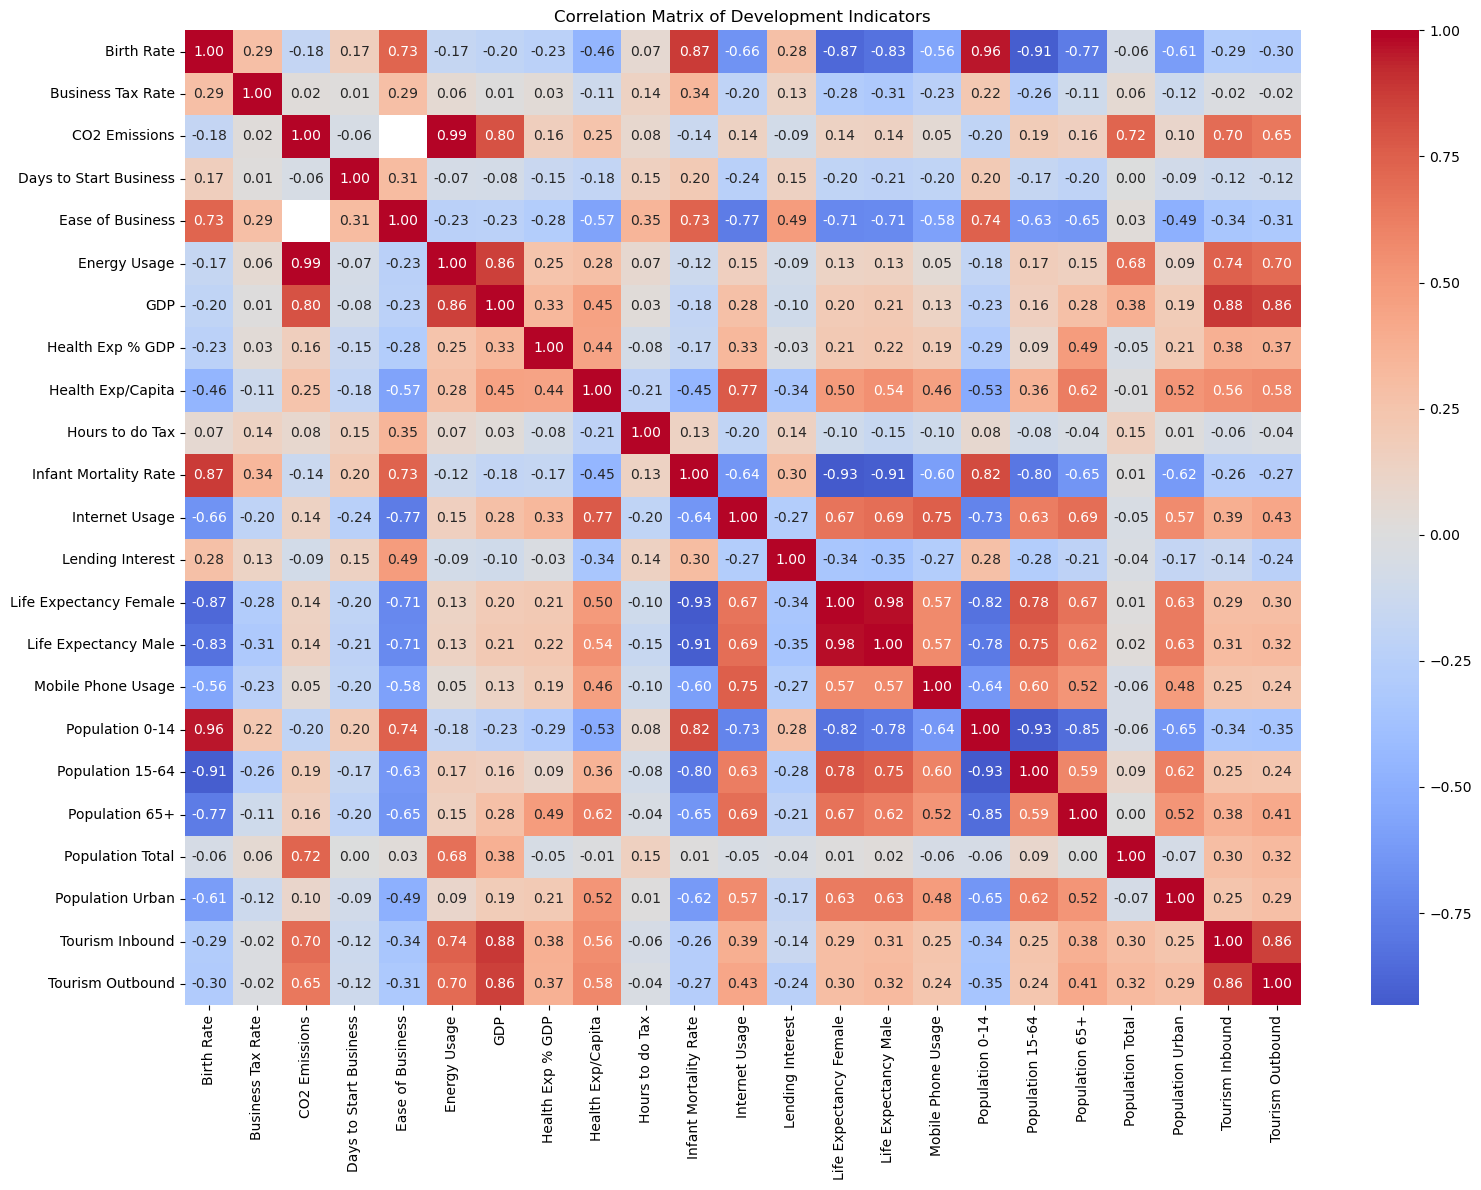

In [35]:
plt.figure(figsize=(16, 12))

sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap="coolwarm",center=0)

plt.title("Correlation Matrix of Development Indicators")
plt.tight_layout()
plt.show()

In [36]:
corr_pairs = (corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack().reset_index())

corr_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]
corr_pairs["Abs_Correlation"] = corr_pairs["Correlation"].abs()
corr_pairs.sort_values("Abs_Correlation",ascending=False).head(20)

,Feature_1,Feature_2,Correlation,Abs_Correlation
44,CO2 Emissions,Energy Usage,0.988715,0.988715
207,Life Expectancy Female,Life Expectancy Male,0.976971,0.976971
15,Birth Rate,Population 0-14,0.955966,0.955966
176,Infant Mortality Rate,Life Expectancy Female,-0.933001,0.933001
231,Population 0-14,Population 15-64,-0.926552,0.926552
16,Birth Rate,Population 15-64,-0.912837,0.912837
177,Infant Mortality Rate,Life Expectancy Male,-0.912240,0.912240
130,GDP,Tourism Inbound,0.879849,0.879849
9,Birth Rate,Infant Mortality Rate,0.872535,0.872535
12,Birth Rate,Life Expectancy Female,-0.868174,0.868174


In [37]:
df_clean.dtypes

Birth Rate                float64
Business Tax Rate         float64
CO2 Emissions             float64
Country                    object
Days to Start Business    float64
Ease of Business          float64
Energy Usage              float64
GDP                       float64
Health Exp % GDP          float64
Health Exp/Capita         float64
Hours to do Tax           float64
Infant Mortality Rate     float64
Internet Usage            float64
Lending Interest          float64
Life Expectancy Female    float64
Life Expectancy Male      float64
Mobile Phone Usage        float64
Number of Records           int64
Population 0-14           float64
Population 15-64          float64
Population 65+            float64
Population Total            int64
Population Urban          float64
Tourism Inbound           float64
Tourism Outbound          float64
dtype: object

In [38]:
df_clean.select_dtypes(include='object').columns

Index(['Country'], dtype='object')

## Prepare One Development Profile per Country
The source dataset contains 2,704 rows for 208 countries, with 13 records per country and no explicit year column. Because this analysis aims to group countries into development profiles, the modelling data below aggregates each numeric indicator by country using the mean, producing one row per country. This is an average profile across the available records, not a time-specific profile. The `Country` column is retained only as an identifier, and `Number of Records` is excluded from clustering features. All preprocessing, scaling, PCA, clustering, evaluation and visualizations after this cell must be rerun on the aggregated data.

In [39]:
# Build one country-level profile by averaging each numeric indicator across its 13 records.
# The source file has no explicit year column, so these are average profiles across available records.
# Keep Country for interpretation, but do not use it as a numeric clustering feature.

numeric_cols = df_clean.select_dtypes(include="number").columns.tolist()

# Aggregate numeric indicators for each country.
df_model = (
    df_clean.groupby("Country", as_index=False)[numeric_cols]
    .mean()
)

print("Country-level dataset shape:", df_model.shape)
print("Unique countries:", df_model["Country"].nunique())
print("Rows per country after aggregation:")
print(df_model["Country"].value_counts().value_counts().sort_index())

# Exclude the country identifier and helper column from clustering features.
exclude_cols = ["Country", "Number of Records"]
feature_cols = [
    col for col in df_model.select_dtypes(include="number").columns
    if col not in exclude_cols
]

# Cap outliers using the IQR method on the country-level profiles.
outlier_summary = []
for col in feature_cols:
    Q1 = df_model[col].quantile(0.25)
    Q3 = df_model[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers_before = ((df_model[col] < lower_limit) | (df_model[col] > upper_limit)).sum()
    df_model[col] = df_model[col].clip(lower=lower_limit, upper=upper_limit)
    outlier_summary.append({"Feature": col, "Outliers Before Capping": int(outliers_before)})

outlier_summary = pd.DataFrame(outlier_summary)
display(outlier_summary)


Country-level dataset shape: (208, 25)
Unique countries: 208
Rows per country after aggregation:
count
1    208
Name: count, dtype: int64


,Feature,Outliers Before Capping
0,Birth Rate,0
1,Business Tax Rate,15
2,CO2 Emissions,29
3,Days to Start Business,18
4,Ease of Business,0
5,Energy Usage,26
6,GDP,26
7,Health Exp % GDP,3
8,Health Exp/Capita,29
9,Hours to do Tax,13


Outlier counts are calculated dynamically in the `outlier_summary` table above. Because the modelling data has already been aggregated to one row per country, do not copy outlier counts from the original 2,704-row dataset into this section.

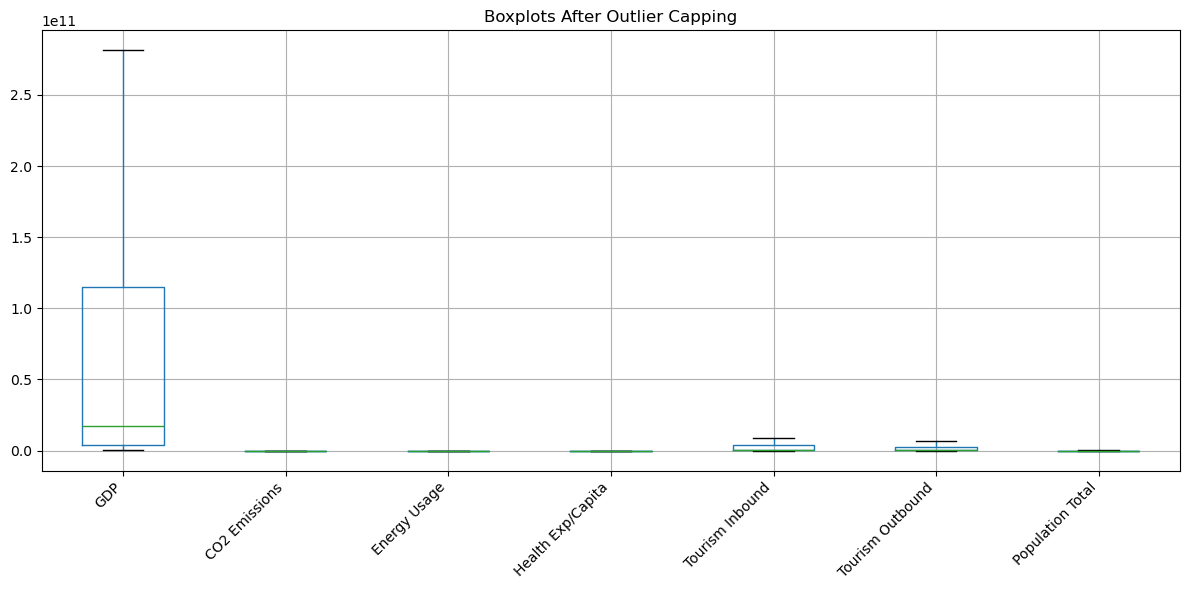

In [40]:
import matplotlib.pyplot as plt

cols = [
    'GDP', 'CO2 Emissions', 'Energy Usage',
    'Health Exp/Capita', 'Tourism Inbound',
    'Tourism Outbound', 'Population Total'
]

df_model[cols].boxplot(figsize=(12, 6))
plt.xticks(rotation=45, ha='right')
plt.title("Boxplots After Outlier Capping")
plt.tight_layout()
plt.show()

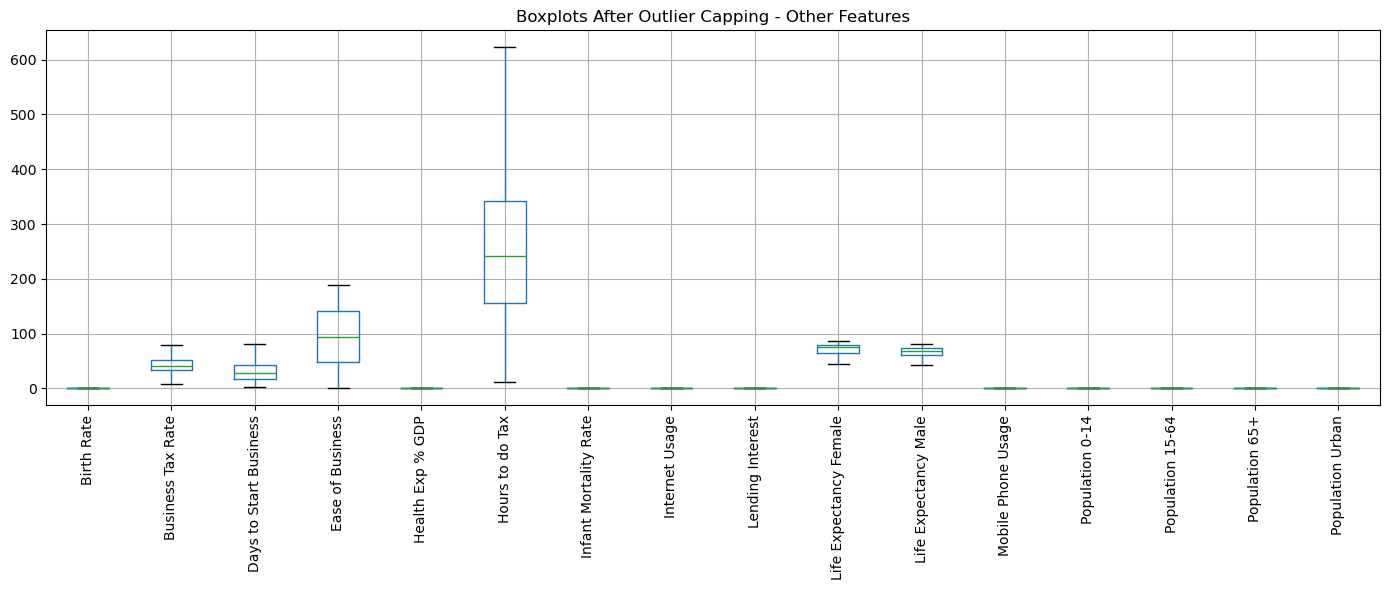

In [41]:
other_cols = [col for col in feature_cols if col not in cols]

df_model[other_cols].boxplot(figsize=(14, 6))
plt.xticks(rotation=90)
plt.title("Boxplots After Outlier Capping - Other Features")
plt.tight_layout()
plt.show()

Outliers were capped using the IQR method to limit the influence of extreme values while retaining the observations. Boxplots were used to visually inspect the distributions after capping.

In [42]:
# Check missing values in the selected numerical features
X = df_model[feature_cols].copy()

X.isnull().sum().sort_values(ascending=False)

Lending Interest          45
Energy Usage              41
Days to Start Business    23
Ease of Business          23
Health Exp % GDP          23
Health Exp/Capita         23
Hours to do Tax           23
Business Tax Rate         23
Tourism Outbound          22
Infant Mortality Rate     20
Population 0-14           16
Tourism Inbound           16
Population 65+            16
Population 15-64          16
CO2 Emissions             13
GDP                       11
Internet Usage             9
Mobile Phone Usage         5
Life Expectancy Male       5
Life Expectancy Female     5
Population Urban           2
Birth Rate                 2
Population Total           0
dtype: int64

In [43]:
missing_summary = pd.DataFrame({
    'Missing Count': X.isnull().sum(),
    'Missing Percentage': (X.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    'Missing Percentage', ascending=False
)

missing_summary

,Missing Count,Missing Percentage
Lending Interest,45,21.63
Energy Usage,41,19.71
Days to Start Business,23,11.06
Ease of Business,23,11.06
Health Exp % GDP,23,11.06
Health Exp/Capita,23,11.06
Hours to do Tax,23,11.06
Business Tax Rate,23,11.06
Tourism Outbound,22,10.58
Infant Mortality Rate,20,9.62


In [44]:
# Remove features with more than 40% missing values
high_missing_cols = missing_summary[
    missing_summary['Missing Percentage'] > 40
].index.tolist()

print("Features removed:", high_missing_cols)

X = X.drop(columns=high_missing_cols)

# Impute remaining missing values using the median
X = X.fillna(X.median())

print("Remaining missing values:", X.isnull().sum().sum())
print("Final feature matrix shape:", X.shape)

Features removed: []
Remaining missing values: 0
Final feature matrix shape: (208, 23)


Features with more than 40% missing values were excluded from the clustering input. Missing values in the remaining numerical features were imputed using their median values.

In [45]:
# Standardize features because the indicators have different units and scales.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (208, 23)


StandardScaler was applied to standardize the selected numerical features so that variables with larger numerical ranges would not dominate distance-based clustering.

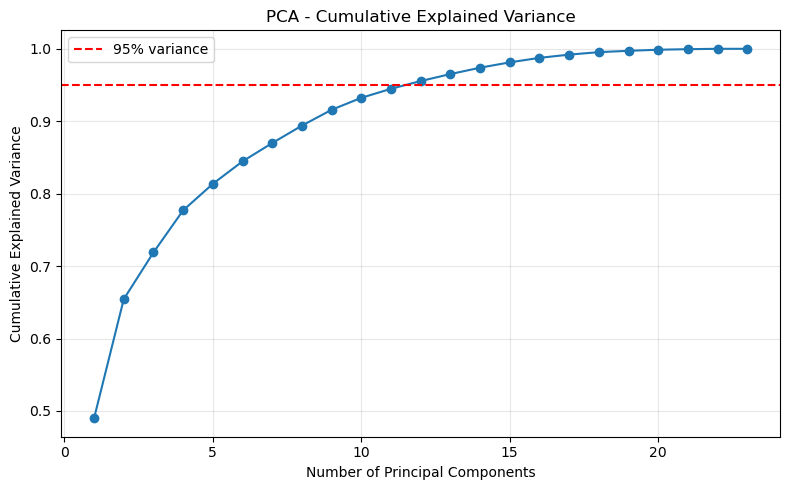

Original number of features: 23
Selected PCA components: 12
Total explained variance: 0.9555
PCA data shape: (208, 12)


In [46]:
# PCA reduces dimensionality while retaining at least 95% of the variance.
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(y=0.95, linestyle="--", color="red", label="95% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Select the minimum number of components needed to retain 95% variance
n_components = int(np.argmax(cumulative_variance >= 0.95) + 1)

pca_model = PCA(n_components=n_components)
X_pca = pca_model.fit_transform(X_scaled)

print("Original number of features:", X_scaled.shape[1])
print("Selected PCA components:", n_components)
print("Total explained variance:", round(pca_model.explained_variance_ratio_.sum(), 4))
print("PCA data shape:", X_pca.shape)


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

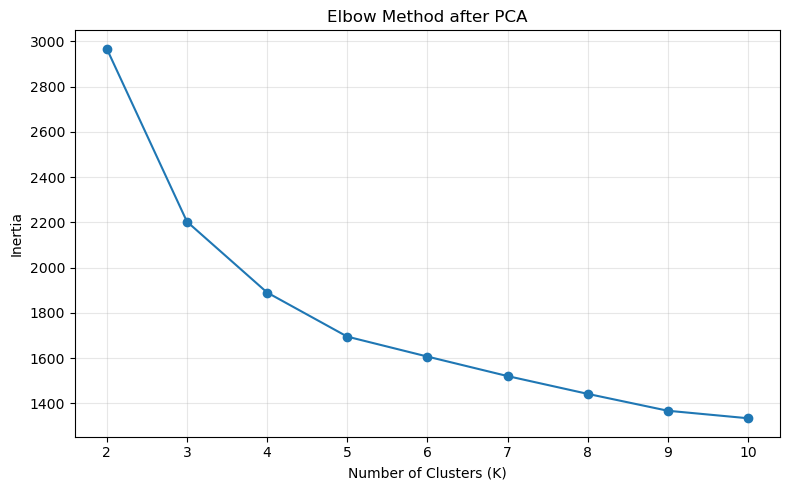

In [47]:
# Elbow Method using PCA-transformed features
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_pca)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method after PCA")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

Evaluation metrics for every tested K (2 through 10):


,K,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,2,0.2906,111.3314,1.2605
1,3,0.2956,110.1837,1.2260
2,4,0.3069,96.4887,1.1365
3,5,0.2238,86.1409,1.3926
4,6,0.1990,74.5554,1.4142
5,7,0.1861,67.2316,1.5872
6,8,0.1613,62.0283,1.6468
7,9,0.1711,58.3123,1.6688
8,10,0.1684,53.4036,1.6428


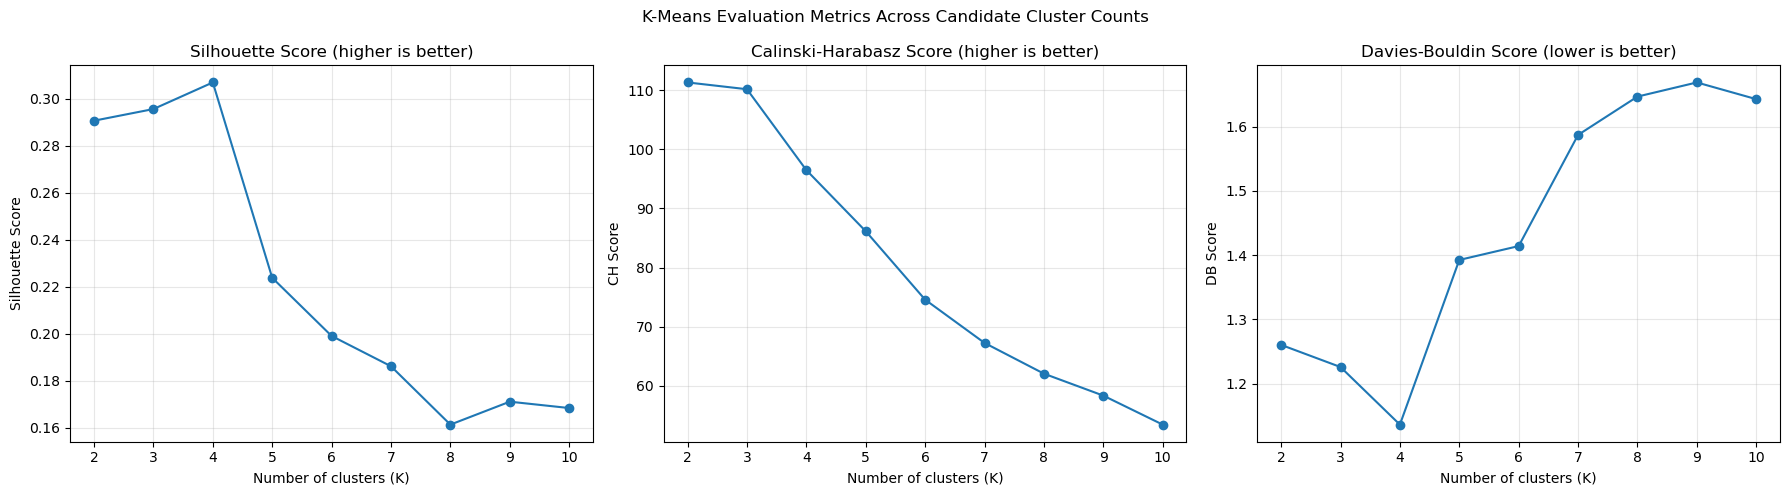

Best K by Silhouette Score alone: 4
Select the final K by considering the Elbow curve, all three metrics, cluster sizes, and interpretability—not one metric alone.


In [48]:
# Evaluate ALL candidate K values using PCA-transformed features
# For every K from 2 to 10, calculate Silhouette, Calinski-Harabasz (CH), and Davies-Bouldin (DB).
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import pandas as pd
import matplotlib.pyplot as plt

k_results = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_pca)

    k_results.append({
        "K": k,
        "Silhouette Score": silhouette_score(X_pca, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X_pca, labels),
        "Davies-Bouldin Score": davies_bouldin_score(X_pca, labels)
    })

k_results_df = pd.DataFrame(k_results)
print("Evaluation metrics for every tested K (2 through 10):")
display(k_results_df.round(4))

# Plot each metric separately so the trend across all candidate K values is easy to inspect.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(k_results_df["K"], k_results_df["Silhouette Score"], marker="o")
axes[0].set_title("Silhouette Score (higher is better)")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Silhouette Score")
axes[0].set_xticks(list(k_values))
axes[0].grid(alpha=0.3)

axes[1].plot(k_results_df["K"], k_results_df["Calinski-Harabasz Score"], marker="o")
axes[1].set_title("Calinski-Harabasz Score (higher is better)")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("CH Score")
axes[1].set_xticks(list(k_values))
axes[1].grid(alpha=0.3)

axes[2].plot(k_results_df["K"], k_results_df["Davies-Bouldin Score"], marker="o")
axes[2].set_title("Davies-Bouldin Score (lower is better)")
axes[2].set_xlabel("Number of clusters (K)")
axes[2].set_ylabel("DB Score")
axes[2].set_xticks(list(k_values))
axes[2].grid(alpha=0.3)

plt.suptitle("K-Means Evaluation Metrics Across Candidate Cluster Counts")
plt.tight_layout()
plt.show()

best_k_by_silhouette = int(
    k_results_df.loc[k_results_df["Silhouette Score"].idxmax(), "K"]
)
print("Best K by Silhouette Score alone:", best_k_by_silhouette)
print("Select the final K by considering the Elbow curve, all three metrics, cluster sizes, and interpretability—not one metric alone.")


In [49]:
# Final K-Means model
# K=4 is retained based on the current metrics, cluster interpretability, and country-profile objective.
selected_k = 4  # Change if the evidence supports K=2, 3, 5, etc.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import pandas as pd

kmeans = KMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=10
)
kmeans_labels = kmeans.fit_predict(X_pca)
df_model["KMeans_Cluster"] = kmeans_labels

print(f"K-Means results for selected K={selected_k}")
print("Cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())
print("Silhouette Score:", round(silhouette_score(X_pca, kmeans_labels), 4))
print("Calinski-Harabasz Score:", round(calinski_harabasz_score(X_pca, kmeans_labels), 4))
print("Davies-Bouldin Score:", round(davies_bouldin_score(X_pca, kmeans_labels), 4))


K-Means results for selected K=4
Cluster sizes:
0    67
1    23
2    29
3    89
Name: count, dtype: int64
Silhouette Score: 0.3069
Calinski-Harabasz Score: 96.4887
Davies-Bouldin Score: 1.1365


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Variance explained by 2D visualization: 65.44 %


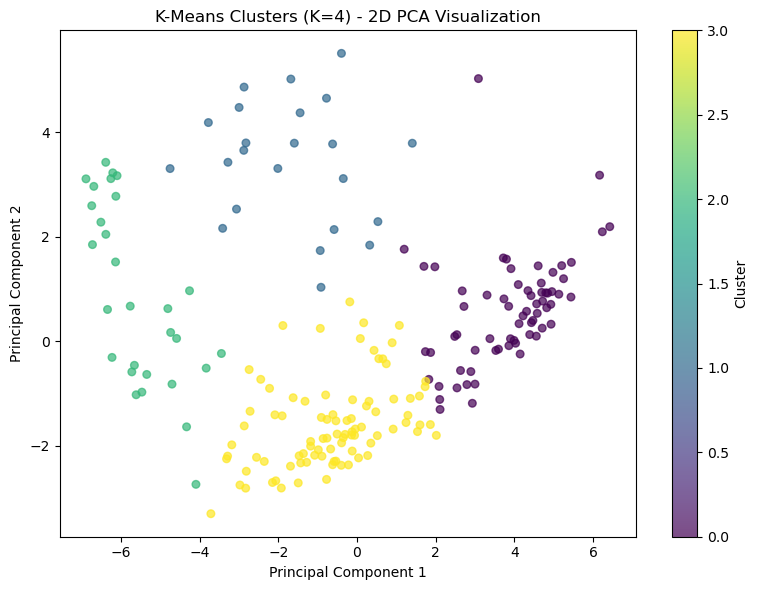

In [50]:
# Visualize K-Means labels in a separate 2D PCA projection
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

print(
    "Variance explained by 2D visualization:",
    round(pca_2d.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    alpha=0.7,
    s=30
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"K-Means Clusters (K={selected_k}) - 2D PCA Visualization")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()


The plot shows the K-Means assignments projected onto the first two principal components for visualization. The clustering itself was performed using the PCA representation retaining at least 95% of variance. The 2D plot may show overlap because it displays only two components. Interpret separation together with the evaluation metrics, not from the plot alone.

The 2D PCA projection is for visualization only; clustering uses all retained PCA components.

In [51]:
# Agglomerative (Hierarchical) Clustering using the same PCA features
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

hierarchical = AgglomerativeClustering(
    n_clusters=selected_k,
    linkage="ward"
)
hierarchical_labels = hierarchical.fit_predict(X_pca)
df_model["Hierarchical_Cluster"] = hierarchical_labels

print("Hierarchical cluster sizes:")
print(df_model["Hierarchical_Cluster"].value_counts().sort_index())
print("Silhouette Score:", round(silhouette_score(X_pca, hierarchical_labels), 4))
print("Calinski-Harabasz Score:", round(calinski_harabasz_score(X_pca, hierarchical_labels), 4))
print("Davies-Bouldin Score:", round(davies_bouldin_score(X_pca, hierarchical_labels), 4))


Hierarchical cluster sizes:
Hierarchical_Cluster
0    42
1    63
2    56
3    47
Name: count, dtype: int64
Silhouette Score: 0.1842
Calinski-Harabasz Score: 79.3644
Davies-Bouldin Score: 1.6087


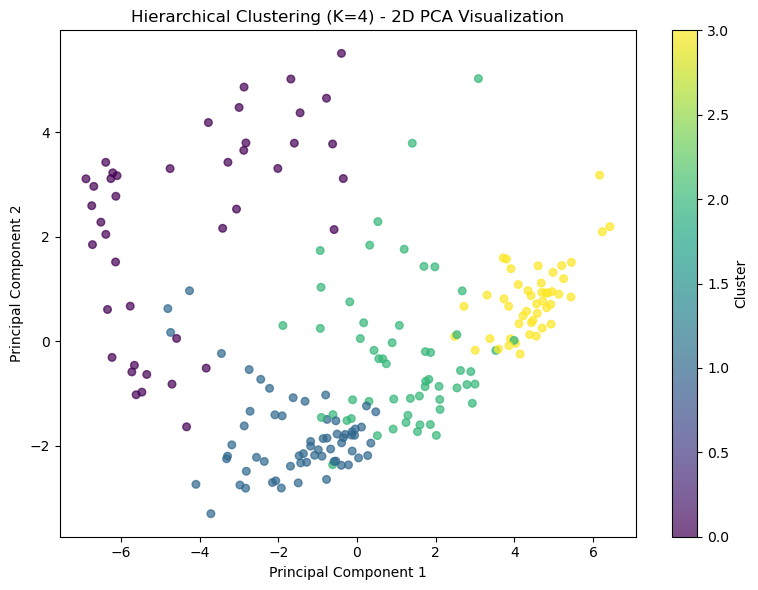

In [52]:
# Visualize Hierarchical Clustering in the same 2D PCA projection
plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=hierarchical_labels,
    cmap="viridis",
    alpha=0.7,
    s=30
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"Hierarchical Clustering (K={selected_k}) - 2D PCA Visualization")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()


Hierarchical clustering uses Ward linkage to form the selected number of clusters from the PCA-transformed features. Compare its Silhouette, Calinski-Harabasz and Davies-Bouldin scores with K-Means. The cluster labels are arbitrary identifiers; their numbers do not indicate rank or development level.

## DBSCAN: Parameter Tuning and Final Model

DBSCAN groups observations by density and labels points outside dense regions as `-1` (noise). It does not require a preset number of clusters. The tuning table tests multiple `eps` and `min_samples` combinations. Select parameters by considering the cluster count, noise percentage, and metrics together—not by choosing the highest Silhouette Score alone.

For DBSCAN, evaluation metrics below are calculated on non-noise observations only, so they are not directly comparable with metrics calculated over all 208 profiles by the other models.

In [53]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)
import pandas as pd
import numpy as np

dbscan_results = []

# Test different parameter combinations
for eps in [0.3, 0.5, 0.7, 0.8, 1.0, 1.2, 1.5, 2.0, 2.5, 3.0]:
    for min_samples in [3, 5, 10]:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_pca)

        # DBSCAN labels noise as -1. Calculate metrics on non-noise points only;
        # interpret these scores alongside noise percentage and cluster count.
        mask = labels != -1
        valid_labels = labels[mask]
        valid_data = X_pca[mask]

        n_clusters = len(set(valid_labels))
        noise_count = int(np.sum(labels == -1))

        row = {
            "eps": eps,
            "min_samples": min_samples,
            "Clusters": n_clusters,
            "Noise Points": noise_count,
            "Silhouette Score": np.nan,
            "CH Score": np.nan,
            "DB Score": np.nan
        }

        if 2 <= n_clusters < len(valid_labels):
            row["Silhouette Score"] = silhouette_score(
                valid_data, valid_labels
            )
            row["CH Score"] = calinski_harabasz_score(
                valid_data, valid_labels
            )
            row["DB Score"] = davies_bouldin_score(
                valid_data, valid_labels
            )

        dbscan_results.append(row)

dbscan_tuning_df = pd.DataFrame(dbscan_results)

# A high silhouette score can be misleading when most observations are marked as noise.
# Prefer a useful cluster count and a reasonable noise percentage, not silhouette alone.
display(
    dbscan_tuning_df.sort_values(
        "Silhouette Score",
        ascending=False,
        na_position="last"
    ).round(4)
)

,eps,min_samples,Clusters,Noise Points,Silhouette Score,CH Score,DB Score
12,1.0,3,3,198,0.6158,131.4315,0.4774
15,1.2,3,3,198,0.6158,131.4315,0.4774
9,0.8,3,2,201,0.5148,11.6776,0.6390
22,2.0,5,3,132,0.4679,72.7795,0.6601
26,2.5,10,2,117,0.3990,58.1468,0.8306
21,2.0,3,4,118,0.3801,70.3052,1.0834
18,1.5,3,4,180,0.3777,37.8401,0.7851
24,2.5,3,2,56,0.1777,4.2825,1.0487
0,0.3,3,0,208,NaN,NaN,NaN
1,0.3,5,0,208,NaN,NaN,NaN


In [54]:
# Final DBSCAN model
# Use the tuning-table trade-off selected for this notebook: eps=2.5 and min_samples=3.
# This setting gave 2 clusters and 56 noise points in the tuning table; note the modest Silhouette score.
selected_eps = 2.5
selected_min_samples = 3
dbscan = DBSCAN(eps=selected_eps, min_samples=selected_min_samples)
dbscan_labels = dbscan.fit_predict(X_pca)
df_model["DBSCAN_Cluster"] = dbscan_labels

print(f"Selected DBSCAN parameters: eps={selected_eps}, min_samples={selected_min_samples}")
print("DBSCAN cluster sizes (including noise):")
print(pd.Series(dbscan_labels).value_counts().sort_index())
print("Number of clusters excluding noise:", len(set(dbscan_labels) - {-1}))
print("Noise points:", int(np.sum(dbscan_labels == -1)))

non_noise = dbscan_labels != -1
valid_labels = dbscan_labels[non_noise]
valid_data = X_pca[non_noise]
n_clusters = len(set(valid_labels))

if 2 <= n_clusters < len(valid_labels):
    print("Silhouette Score (excluding noise):", round(silhouette_score(valid_data, valid_labels), 4))
    print("Calinski-Harabasz Score (excluding noise):", round(calinski_harabasz_score(valid_data, valid_labels), 4))
    print("Davies-Bouldin Score (excluding noise):", round(davies_bouldin_score(valid_data, valid_labels), 4))
else:
    print("Clustering metrics are undefined because DBSCAN did not produce at least two non-noise clusters.")


Selected DBSCAN parameters: eps=2.5, min_samples=3
DBSCAN cluster sizes (including noise):
-1     56
 0    149
 1      3
Name: count, dtype: int64
Number of clusters excluding noise: 2
Noise points: 56
Silhouette Score (excluding noise): 0.1777
Calinski-Harabasz Score (excluding noise): 4.2825
Davies-Bouldin Score (excluding noise): 1.0487


DBSCAN groups observations based on density and labels noise points as -1. Its eps parameter was evaluated using a tuning table. The final interpretation should report the actual cluster count, noise count and metrics produced by the selected eps; do not reuse results from an earlier run or a different feature representation.

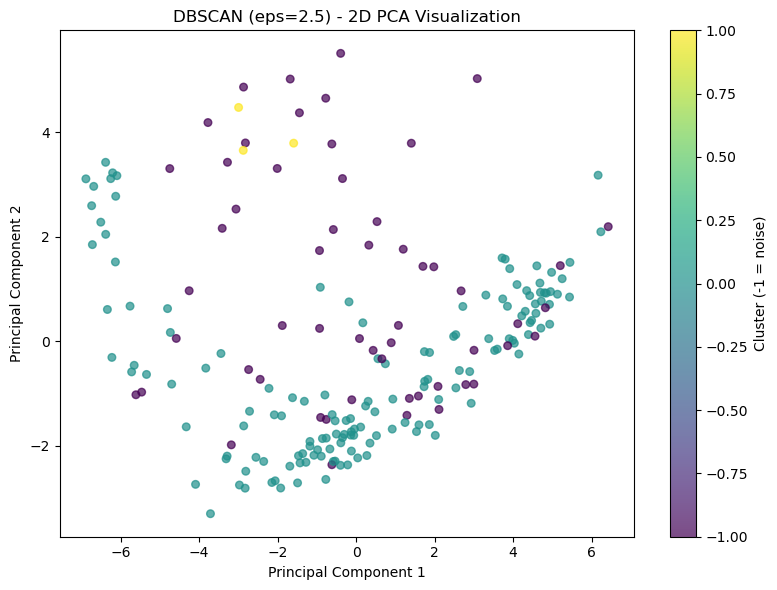

In [55]:
# Visualize DBSCAN assignments in the 2D PCA projection
plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    alpha=0.7,
    s=30
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"DBSCAN (eps={selected_eps}) - 2D PCA Visualization")
plt.colorbar(label="Cluster (-1 = noise)")
plt.tight_layout()
plt.show()


In [56]:
# Gaussian Mixture Model (GMM) using PCA-transformed features
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

gmm = GaussianMixture(
    n_components=selected_k,
    random_state=42,
    n_init=5
)
gmm_labels = gmm.fit_predict(X_pca)
df_model["GMM_Cluster"] = gmm_labels

print("GMM cluster sizes:")
print(pd.Series(gmm_labels).value_counts().sort_index())
print("Silhouette Score:", round(silhouette_score(X_pca, gmm_labels), 4))
print("Calinski-Harabasz Score:", round(calinski_harabasz_score(X_pca, gmm_labels), 4))
print("Davies-Bouldin Score:", round(davies_bouldin_score(X_pca, gmm_labels), 4))


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

GMM cluster sizes:
0    47
1    51
2    62
3    48
Name: count, dtype: int64
Silhouette Score: 0.175
Calinski-Harabasz Score: 78.3076
Davies-Bouldin Score: 1.6945


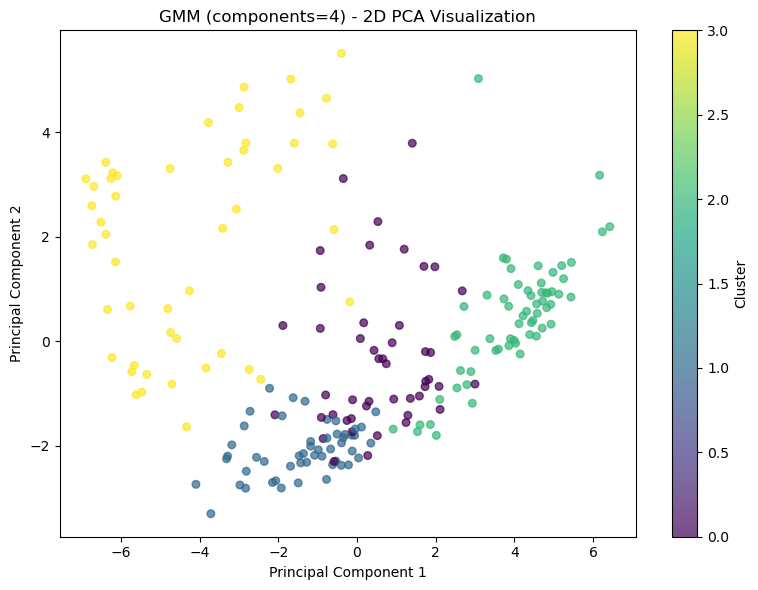

In [57]:
# Visualize GMM clusters in the 2D PCA projection
plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=gmm_labels, cmap="viridis", alpha=0.7, s=30
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"GMM (components={selected_k}) - 2D PCA Visualization")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()


In [58]:
# BIRCH using PCA-transformed features
from sklearn.cluster import Birch
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

birch = Birch(n_clusters=selected_k)
birch_labels = birch.fit_predict(X_pca)
df_model["BIRCH_Cluster"] = birch_labels

print("BIRCH cluster sizes:")
print(pd.Series(birch_labels).value_counts().sort_index())
print("Silhouette Score:", round(silhouette_score(X_pca, birch_labels), 4))
print("Calinski-Harabasz Score:", round(calinski_harabasz_score(X_pca, birch_labels), 4))
print("Davies-Bouldin Score:", round(davies_bouldin_score(X_pca, birch_labels), 4))


BIRCH cluster sizes:
0    47
1    49
2    47
3    65
Name: count, dtype: int64
Silhouette Score: 0.1946
Calinski-Harabasz Score: 82.3827
Davies-Bouldin Score: 1.5992


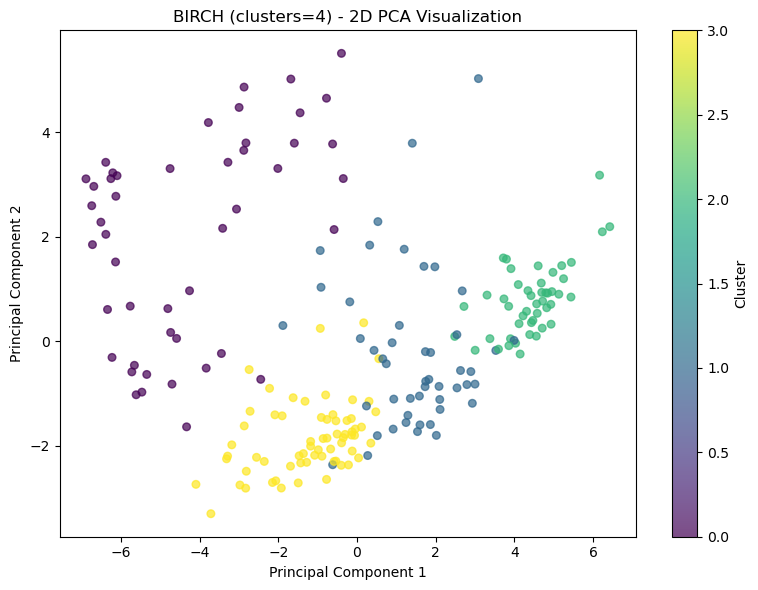

In [59]:
# Visualize BIRCH clusters in the 2D PCA projection
plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=birch_labels, cmap="viridis", alpha=0.7, s=30
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"BIRCH (clusters={selected_k}) - 2D PCA Visualization")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()


In [60]:
# MiniBatch K-Means using PCA-transformed features
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

mini_kmeans = MiniBatchKMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=10,
    batch_size=256
)
mini_labels = mini_kmeans.fit_predict(X_pca)
df_model["MiniBatchKMeans_Cluster"] = mini_labels

print("MiniBatch K-Means cluster sizes:")
print(pd.Series(mini_labels).value_counts().sort_index())
print("Silhouette Score:", round(silhouette_score(X_pca, mini_labels), 4))
print("Calinski-Harabasz Score:", round(calinski_harabasz_score(X_pca, mini_labels), 4))
print("Davies-Bouldin Score:", round(davies_bouldin_score(X_pca, mini_labels), 4))


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1955: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 2560 or by setting the environment variable OMP_NUM_THREADS=1
  warnings.warn(


MiniBatch K-Means cluster sizes:
0    23
1    89
2    67
3    29
Name: count, dtype: int64
Silhouette Score: 0.3069
Calinski-Harabasz Score: 96.4887
Davies-Bouldin Score: 1.1365


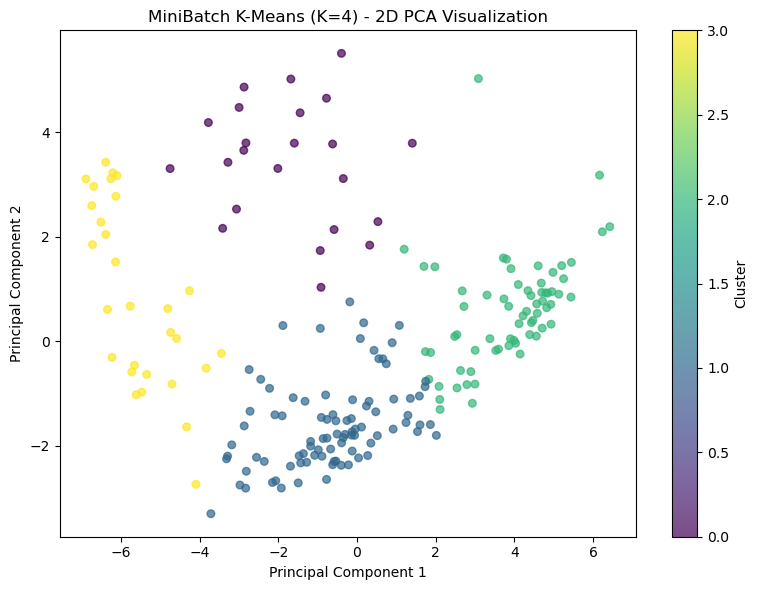

In [61]:
# Visualize MiniBatch K-Means clusters in the 2D PCA projection
plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=mini_labels, cmap="viridis", alpha=0.7, s=30
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"MiniBatch K-Means (K={selected_k}) - 2D PCA Visualization")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()


### How the models are compared

The same 12 PCA components are supplied to K-Means, Agglomerative Clustering, GMM, BIRCH, MiniBatch K-Means, and DBSCAN. Higher Silhouette and Calinski–Harabasz scores are generally preferred; lower Davies–Bouldin scores are generally preferred. For DBSCAN, noise points are excluded from the metric calculations, so its scores require a separate caveat.

## Final Model Comparison

Compare all six models on the same PCA-transformed feature representation. For DBSCAN, noise points are excluded from the metric calculations, so its scores must be interpreted with its noise count and number of clusters.

In [62]:
# Compare all models on the same PCA-transformed data for a fairer evaluation.
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import pandas as pd
import numpy as np

model_outputs = [
    ("K-Means", kmeans_labels),
    ("Agglomerative", hierarchical_labels),
    ("Gaussian Mixture Model", gmm_labels),
    ("BIRCH", birch_labels),
    ("MiniBatch K-Means", mini_labels),
    ("DBSCAN", dbscan_labels)
]

comparison_results = []

for name, labels in model_outputs:
    # DBSCAN noise points (-1) are excluded from metric calculation. Therefore, DBSCAN scores
    # are not perfectly comparable to scores calculated on all observations for other models.
    mask = labels != -1
    y = labels[mask]
    X_eval = X_pca[mask]
    n_clusters = len(np.unique(y))

    row = {
        "Model": name,
        "Clusters (excluding noise)": n_clusters,
        "Noise Points": int(np.sum(labels == -1)),
        "Silhouette Score": np.nan,
        "Calinski-Harabasz Score": np.nan,
        "Davies-Bouldin Score": np.nan
    }

    if 2 <= n_clusters < len(y):
        row["Silhouette Score"] = silhouette_score(X_eval, y)
        row["Calinski-Harabasz Score"] = calinski_harabasz_score(X_eval, y)
        row["Davies-Bouldin Score"] = davies_bouldin_score(X_eval, y)

    comparison_results.append(row)

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df.round(4))


,Model,Clusters (excluding noise),Noise Points,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,K-Means,4,0,0.3069,96.4887,1.1365
1,Agglomerative,4,0,0.1842,79.3644,1.6087
2,Gaussian Mixture Model,4,0,0.1750,78.3076,1.6945
3,BIRCH,4,0,0.1946,82.3827,1.5992
4,MiniBatch K-Means,4,0,0.3069,96.4887,1.1365
5,DBSCAN,2,56,0.1777,4.2825,1.0487


### K-Means vs MiniBatch K-Means
Compare the two partitions with Adjusted Rand Index (ARI). ARI = 1.0 indicates identical groupings even if the cluster numbers are permuted.

In [63]:

from sklearn.metrics import adjusted_rand_score

print("K-Means cluster sizes:")
print(df_model["KMeans_Cluster"].value_counts().sort_index())

print("\nMiniBatch K-Means cluster sizes:")
print(df_model["MiniBatchKMeans_Cluster"].value_counts().sort_index())

ari = adjusted_rand_score(
    df_model["KMeans_Cluster"],
    df_model["MiniBatchKMeans_Cluster"]
)

print("\nAdjusted Rand Index:", round(ari, 4))

K-Means cluster sizes:
KMeans_Cluster
0    67
1    23
2    29
3    89
Name: count, dtype: int64

MiniBatch K-Means cluster sizes:
MiniBatchKMeans_Cluster
0    23
1    89
2    67
3    29
Name: count, dtype: int64

Adjusted Rand Index: 1.0


## Interpret the selected K-Means clusters

The following table summarizes the original numeric indicators (not PCA components) within each K-Means cluster. Use these averages to describe the groups. Cluster IDs are arbitrary and do not represent a ranking.

In [64]:
# Summarize original indicator values by the final K-Means cluster; exclude helper and label columns.
cluster_cols = [
    "KMeans_Cluster",
    "Hierarchical_Cluster",
    "DBSCAN_Cluster",
    "GMM_Cluster",
    "BIRCH_Cluster",
    "MiniBatchKMeans_Cluster"
]

original_features = df_model.drop(
    columns=cluster_cols + ["Number of Records"],
    errors="ignore"
)

cluster_profile = original_features.groupby(
    df_model["KMeans_Cluster"]
).mean(numeric_only=True)

display(cluster_profile.round(2))

,Birth Rate,Business Tax Rate,CO2 Emissions,Days to Start Business,Ease of Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,Hours to do Tax,...,Life Expectancy Female,Life Expectancy Male,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
KMeans_Cluster,,,,,,,,,,,,,,,,,,,,,
0,0.04,47.46,9080.47,45.64,146.32,9132.92,1.424801e+10,0.06,67.58,302.32,...,58.85,56.09,0.24,0.42,0.55,0.03,13474259.38,0.35,2.183273e+08,2.577375e+08
1,0.02,49.72,134423.81,36.55,92.96,64767.37,2.149897e+11,0.05,275.10,386.77,...,73.54,67.48,0.60,0.28,0.66,0.07,42447225.22,0.60,5.384803e+09,4.392382e+09
2,0.01,41.67,93207.07,16.43,26.45,45806.77,2.327483e+11,0.09,1401.75,185.48,...,82.19,76.91,1.00,0.18,0.68,0.15,19989171.99,0.80,7.380302e+09,5.807167e+09
3,0.02,37.39,16146.73,29.38,75.53,7185.24,2.192186e+10,0.06,495.48,244.47,...,76.89,71.15,0.68,0.26,0.66,0.08,3977073.72,0.63,1.256189e+09,6.387047e+08


In [65]:
country_clusters = df_model[["Country", "KMeans_Cluster"]].sort_values(
    by=["KMeans_Cluster", "Country"]
)

display(country_clusters)

,Country,KMeans_Cluster
0,Afghanistan,0
5,Angola,0
15,Bangladesh,0
20,Benin,0
22,Bhutan,0
...,...,...
190,Tunisia,3
193,Turks and Caicos Islands,3
199,Uruguay,3
201,Vanuatu,3


In [66]:
print("Scaled data shape:", X_scaled.shape)
print("Feature count:", len(feature_cols))
print("Country column included in features:", "Country" in feature_cols)
print("Cluster labels included in features:",
      any("Cluster" in col for col in feature_cols))
print("Scaler:", type(scaler).__name__)

Scaled data shape: (208, 23)
Feature count: 23
Country column included in features: False
Cluster labels included in features: False
Scaler: StandardScaler


In [67]:
print("Scaler feature count:", scaler.n_features_in_)
print("K-Means feature count:", kmeans.n_features_in_)
print("Feature counts match:",
      scaler.n_features_in_ == kmeans.n_features_in_)

print("K-Means fitted:", hasattr(kmeans, "cluster_centers_"))
print("Scaler fitted:", hasattr(scaler, "mean_"))

Scaler feature count: 23
K-Means feature count: 12
Feature counts match: False
K-Means fitted: True
Scaler fitted: True


## Conclusion

The original dataset contained 2,704 rows for 208 countries, with 13 records per country and no explicit year column. Numeric indicators were averaged by country to create 208 country-level profiles. The numeric features were then checked for outliers and missing values, standardized with `StandardScaler`, and transformed using PCA.

PCA retained **at least 95% of the variance** in the standardized features. In the current run, 12 principal components retained approximately **95.55%** of the variance from 23 input features. All six clustering algorithms were evaluated on the same PCA representation.

Based on the reported country-level comparison, **K-Means with K = 4 is the recommended model** among the algorithms that assign all profiles to clusters. It achieved a Silhouette Score of **0.3069**, a Calinski–Harabasz Score of **96.4887**, and a Davies–Bouldin Score of **1.1365**. MiniBatch K-Means produced the same partition (Adjusted Rand Index = **1.0**) and the same reported metrics, so it is effectively tied; standard K-Means is retained as the simpler, familiar final choice.

DBSCAN was difficult to use for this dataset under the tested settings because it left a substantial number of profiles as noise. Its scores are computed only on non-noise profiles and should not be compared directly with the other models' scores. The tuning table and final run should be interpreted using cluster count and noise percentage alongside the metrics.

The four K-Means clusters are groups of similar indicator profiles, not official development rankings. Cluster IDs are arbitrary. Use the cluster-profile table to describe their differences, and avoid calling a cluster “developed” or “developing” unless the interpretation is supported by the underlying indicators and a clearly stated definition.



We selected K-Means as our final clustering algorithm because it produced the same clustering results as MiniBatch K-Means. Since our aggregated dataset contains only 208 country-level records, the computational efficiency advantage of MiniBatch K-Means was not necessary. Therefore, we preferred standard K-Means for its simplicity and suitability for our dataset.

In [68]:

# STEP 1: Save the trained model and preprocessing objects

import joblib
import numpy as np

# Check that the required objects have been created
assert hasattr(kmeans, "cluster_centers_"), "Run the K-Means training cell first."
assert hasattr(scaler, "mean_"), "Run the scaler cell first."
assert hasattr(pca_model, "components_"), "Run the PCA cell first."

# Recalculate the original country-level profiles to obtain
# the same outlier limits used during model training.
numeric_cols = df_clean.select_dtypes(include="number").columns.tolist()

country_raw = (
    df_clean.groupby("Country", as_index=False)[numeric_cols]
    .mean()
)

raw_feature_cols = [
    col for col in country_raw.select_dtypes(include="number").columns
    if col not in ["Number of Records"]
]

# Calculate the IQR clipping limits before outlier capping
clip_bounds = {}

for col in raw_feature_cols:
    q1 = country_raw[col].quantile(0.25)
    q3 = country_raw[col].quantile(0.75)
    iqr = q3 - q1

    clip_bounds[col] = (
        float(q1 - 1.5 * iqr),
        float(q3 + 1.5 * iqr)
    )

# Save medians and the exact feature order used for training
feature_names = X.columns.tolist()
medians = X[feature_names].median().to_dict()

# Bundle everything the Streamlit app needs
model_bundle = {
    "feature_names": feature_names,
    "clip_bounds": clip_bounds,
    "medians": medians,
    "scaler": scaler,
    "pca": pca_model,
    "kmeans": kmeans,
    "selected_k": selected_k
}

# Verify feature dimensions before saving
assert scaler.n_features_in_ == len(feature_names)
assert pca_model.n_features_in_ == len(feature_names)
assert kmeans.n_features_in_ == pca_model.n_components_

joblib.dump(model_bundle, "clustering_model_bundle.pkl")

print("Model bundle saved successfully!")
print("Features:", len(feature_names))
print("Selected clusters:", selected_k)
print("Saved file: clustering_model_bundle.pkl")


Model bundle saved successfully!
Features: 23
Selected clusters: 4
Saved file: clustering_model_bundle.pkl
